Oklahoma's child support guideline schedule (43 O.S. § 119)[^statute] has not changed in nominal terms since 1999,
and it stops at \$15,000 in combined gross monthly income. This report measures what that freeze has
done to the share of parental income the schedule assigns across the income distribution, and to the
share of Oklahoma families it covers at all.

The schedule is the legislature's own statement of what raising a child costs at each income level
and how parents divide that cost. No one has voted to assign children a smaller share of their
parents' income than in 1999, yet leaving the table untouched has done that in practice. Tax policy
calls this mechanism bracket creep: fixed dollar brackets meet rising nominal incomes, and the burden
shifts without a vote. Here it runs in reverse. Rising incomes carry most families down the
schedule's declining share curve and past a cap that has lost 47% of its value. This report
puts numbers on that drift for the next quadrennial review.[^review]

## 1. Setup

Code for every step is folded under the "Show code" buttons. The full notebook, raw and cleaned
data, and data dictionary are in the GitHub repository:
<https://github.com/Scubdog/ok-child-support-schedule>

In [1]:
#| include: false

# Standard library imports
import json
import logging
import re
import textwrap
from pathlib import Path

# Third-party imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pdfplumber
import requests
from matplotlib.transforms import offset_copy
from scipy.stats import gaussian_kde

# File locations
DATA_RAW_DIR = Path("data_raw")
DATA_PROCESSED_DIR = Path("data_processed")
DATA_PROCESSED_DIR.mkdir(exist_ok=True)
SCHEDULE_PDF = DATA_RAW_DIR / "okdhs_pub_01-38_rev2013_2026-09-25.pdf"
OSCN_CURRENT_PDF = DATA_RAW_DIR / "oscn_119_current_2026-09-25.pdf"
OSCN_1999_PDF = DATA_RAW_DIR / "oscn_119_superseded_1999_2026-09-25.pdf"
IPUMS_FILE = Path("usa_00001.csv.gz")

# Schedule parameters (43 O.S. § 119)
INCOME_CAP = 15000
PHASE_IN_START = 650
CHILD_COLUMNS = ["one", "two", "three", "four", "five", "six"]
CHILD_COUNTS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6}

# Imputed full-time minimum wage, monthly (OKDHS Pub. 01-38 minimum wage table)
MIN_WAGE_MONTHLY = {1999: 893, 2024: 1257}

# HHS poverty guideline for one person, 48 states and DC, converted to monthly
# (Federal Register notices of March 18, 1999 and January 17, 2024)
POVERTY_GUIDELINE_MONTHLY = {1999: 8240 / 12, 2024: 15060 / 12}

# Comparison years
BASE_YEAR = 1999
CURRENT_YEAR = 2024

# BLS CPI-U series: U.S. city average and South region, all items
CPI_SERIES_US = "CUUR0000SA0"
CPI_SERIES_SOUTH = "CUUR0300SA0"

# BLS API key, read from a local file that is not uploaded to GitHub
BLS_API_KEY = Path("bls_api_key.txt").read_text().strip()

# Silence harmless font warnings from the state seal image in the OSCN PDFs
logging.getLogger("pdfminer").setLevel(logging.ERROR)


def dollars(value):
    """Format a dollar amount for chart text (escaped so matplotlib shows a plain $)."""
    return "\\$" + f"{value:,.0f}"


def ordinal(number):
    """Return a whole number with its ordinal suffix (1st, 2nd, 3rd, 4th, 11th, 21st)."""
    number = int(round(number))
    if 11 <= number % 100 <= 13:
        return f"{number}th"
    return f"{number}{ {1: 'st', 2: 'nd', 3: 'rd'}.get(number % 10, 'th')}"


def add_legend_below(fig, ax, ncol=2, fontsize=9):
    """Place one legend centered below the figure, built from one axis's entries."""
    handles, labels = ax.get_legend_handles_labels()
    return fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.0),
                      ncol=ncol, frameon=False, fontsize=fontsize)


def add_figure_titles(fig, finding, description, width=95):
    """Title a figure with its finding in bold and a smaller description beneath it.

    The finding wraps at `width` characters so long titles are not clipped when saved.
    """
    finding = textwrap.fill(finding, width=width)
    # The description sits just above the plotting area
    fig.text(0.5, 1.0, description, ha="center", va="bottom", fontsize=10, color="0.35")
    # The finding sits above the description, raised by the description's line count
    description_lines = description.count("\n") + 1
    raised = offset_copy(fig.transFigure, fig=fig, y=14 * description_lines + 4,
                         units="points")
    fig.text(0.5, 1.0, finding, ha="center", va="bottom", fontsize=12, fontweight="bold",
             transform=raised)

## 2. The guideline schedule

The schedule is extracted from OKDHS Pub. 01-38[^dhs] and checked cell by cell against the current
and 1999 statute texts. Each child count has 289 rows: \$50 a month, then \$650 to \$15,000 in
steps of \$50.

In [2]:
#| include: false
# A schedule row is an income followed by six support amounts (seven whole numbers)
SCHEDULE_ROW_PATTERN = re.compile(r"^\d+( \d+){6}$")

# Thousands separators, including the stray space in the OSCN text ("2, 026")
THOUSANDS_PATTERN = re.compile(r"(\d),\s*(\d{3})\b")


def read_schedule_pdf(pdf_path):
    """Extract the guideline schedule from a PDF into a wide DataFrame."""
    rows = []
    with pdfplumber.open(pdf_path) as pdf:
        for page in pdf.pages:
            page_text = page.extract_text() or ""
            for line in page_text.splitlines():
                clean_line = THOUSANDS_PATTERN.sub(r"\1\2", line.strip())
                if SCHEDULE_ROW_PATTERN.match(clean_line):
                    rows.append([int(value) for value in clean_line.split()])
    schedule_df = pd.DataFrame(rows, columns=["combined_monthly_income"] + CHILD_COLUMNS)
    # Repeated pages in the DHS PDF produce duplicate rows; keep one per income
    schedule_df = schedule_df.drop_duplicates(subset="combined_monthly_income")
    schedule_df = schedule_df[schedule_df["combined_monthly_income"] <= INCOME_CAP]
    return schedule_df.sort_values("combined_monthly_income").reset_index(drop=True)

In [3]:
#| include: false
# Extract the schedule from each source
dhs_df = read_schedule_pdf(SCHEDULE_PDF)
oscn_current_df = read_schedule_pdf(OSCN_CURRENT_PDF)
oscn_1999_df = read_schedule_pdf(OSCN_1999_PDF)

# Each should have 289 rows and 7 columns
for source_name, source_df in [("DHS", dhs_df), ("OSCN current", oscn_current_df),
                               ("OSCN 1999", oscn_1999_df)]:
    print(source_name, source_df.shape)

DHS (289, 7)
OSCN current (289, 7)
OSCN 1999 (289, 7)


In [4]:
#| include: false
# Expected income rows: $50, then $650 to $15,000 in $50 steps
expected_incomes = [50] + list(range(650, INCOME_CAP + 1, 50))

for source_name, source_df in [("DHS", dhs_df), ("OSCN current", oscn_current_df),
                               ("OSCN 1999", oscn_1999_df)]:
    grid_matches = source_df["combined_monthly_income"].tolist() == expected_incomes
    # Flag any cell where support falls as income rises
    decreases = source_df[CHILD_COLUMNS].diff().lt(0).stack()
    decrease_cells = [(int(source_df.loc[row, "combined_monthly_income"]), column)
                      for row, column in decreases[decreases].index]
    print(f"{source_name}: grid matches = {grid_matches}, decreases at {decrease_cells}")

DHS: grid matches = True, decreases at []
OSCN current: grid matches = True, decreases at [(7850, 'two'), (11300, 'three')]
OSCN 1999: grid matches = True, decreases at [(11300, 'three')]


In [5]:
#| include: false
def compare_to_dhs(other_df, other_name):
    """Return the cells where another schedule source differs from DHS."""
    dhs_long = dhs_df.melt(id_vars="combined_monthly_income", var_name="children",
                           value_name="dhs")
    other_long = other_df.melt(id_vars="combined_monthly_income", var_name="children",
                               value_name=other_name)
    merged_df = dhs_long.merge(other_long, on=["combined_monthly_income", "children"])
    return merged_df[merged_df["dhs"] != merged_df[other_name]]


print(compare_to_dhs(oscn_current_df, "oscn_current"))
print(compare_to_dhs(oscn_1999_df, "oscn_1999"))

     combined_monthly_income children   dhs  oscn_current
433                     7800      two  1281          1287
434                     7850      two  1287          1281
792                    11300    three  1989          1898
851                    14250    three  2241          2240
     combined_monthly_income children   dhs  oscn_1999
792                    11300    three  1989       1898
851                    14250    three  2241       2240


In [6]:
#| include: false
# One row per income and number of children
schedule_long_df = dhs_df.melt(id_vars="combined_monthly_income", var_name="child_label",
                               value_name="total_support_amount")
schedule_long_df["n_children"] = schedule_long_df["child_label"].map(CHILD_COUNTS)
schedule_long_df = schedule_long_df.drop(columns="child_label")

# Support as a share of combined income
schedule_long_df["support_share"] = (schedule_long_df["total_support_amount"]
                                     / schedule_long_df["combined_monthly_income"])

# Save the cleaned schedule for later parts
schedule_long_df.to_csv(DATA_PROCESSED_DIR / "schedule_long.csv", index=False)
print(schedule_long_df.shape)

(1734, 4)


In [7]:
#| include: false
# Spot-check one-child shares at four income levels
print(schedule_long_df.query(
    "n_children == 1 and combined_monthly_income in [750, 1400, 8000, 15000]"
))

     combined_monthly_income  total_support_amount  n_children  support_share
3                        750                    61           1       0.081333
16                      1400                   273           1       0.195000
148                     8000                   905           1       0.113125
288                    15000                  1372           1       0.091467


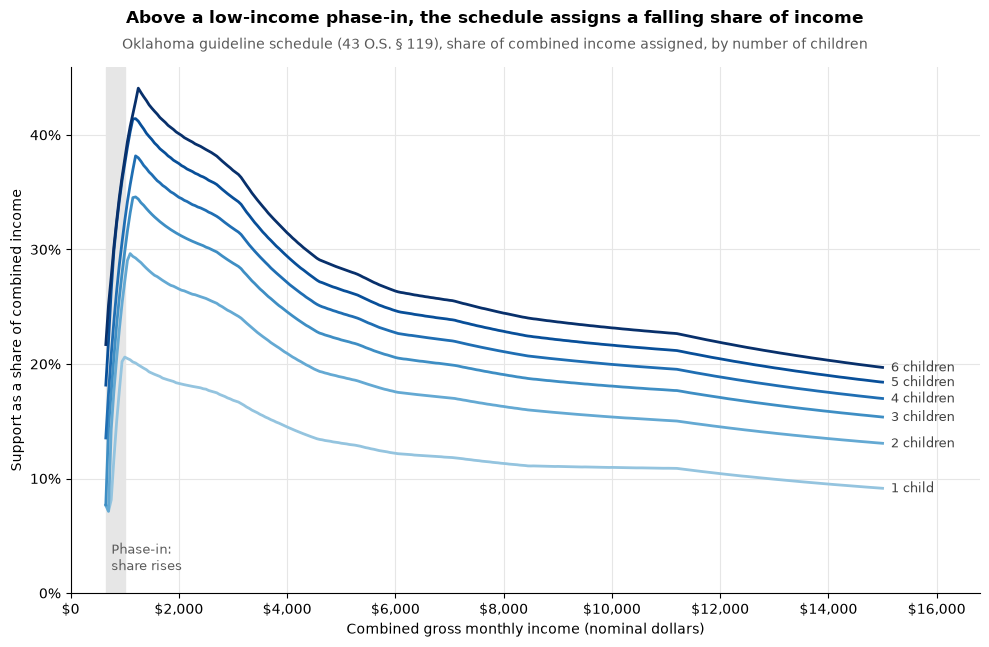

In [8]:
# Plot from 650 up; the 50-dollar minimum row would dominate the vertical axis
plot_df = schedule_long_df[schedule_long_df["combined_monthly_income"] >= PHASE_IN_START]

fig, ax = plt.subplots(figsize=(10, 6))
# One shade of blue per child count, light (1) to dark (6)
line_colors = plt.cm.Blues(np.linspace(0.4, 1.0, 6))
for n_children, color in zip(range(1, 7), line_colors):
    child_df = plot_df[plot_df["n_children"] == n_children]
    ax.plot(child_df["combined_monthly_income"], child_df["support_share"],
            color=color, linewidth=2)
    # Label each line at its right end instead of using a legend
    child_word = "child" if n_children == 1 else "children"
    ax.annotate(f"{n_children} {child_word}",
                (child_df["combined_monthly_income"].iloc[-1],
                 child_df["support_share"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9,
                color="0.25")

# Shade the low-income phase-in, where the share rises with income
peak_income = plot_df.loc[plot_df["n_children"] == 1].set_index(
    "combined_monthly_income")["support_share"].idxmax()
ax.axvspan(PHASE_IN_START, peak_income, color="0.9", zorder=0)
ax.annotate("Phase-in:\nshare rises", (PHASE_IN_START, 0.02), xytext=(4, 0),
            textcoords="offset points", fontsize=9, color="0.35")

ax.set_xlabel("Combined gross monthly income (nominal dollars)")
ax.set_ylabel("Support as a share of combined income")
ax.set_xlim(0, INCOME_CAP * 1.12)
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax.grid(color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
add_figure_titles(fig, "Above a low-income phase-in, the schedule assigns a falling share "
                  "of income",
                  "Oklahoma guideline schedule (43 O.S. § 119), share of combined income "
                  "assigned, by number of children")
plt.show()

## 3. Consumer prices

Prices are annual average CPI-U from the BLS Public Data API.[^bls] The U.S. city average is the
deflator (1.883 from 1999 to 2024); the South region series gives 1.884.

In [9]:
#| include: false
BLS_API_URL = "https://api.bls.gov/publicAPI/v2/timeseries/data/"
# A registered key allows at most 20 years per request
BLS_MAX_YEARS = 20


def fetch_cpi_annual(series_ids, start_year, end_year):
    """Pull annual average CPI for each series, in chunks of up to 20 years."""
    all_series = []
    for chunk_start in range(start_year, end_year + 1, BLS_MAX_YEARS):
        chunk_end = min(chunk_start + BLS_MAX_YEARS - 1, end_year)
        payload = {
            "seriesid": series_ids,
            "startyear": str(chunk_start),
            "endyear": str(chunk_end),
            "annualaverage": True,
            "registrationkey": BLS_API_KEY,
        }
        response = requests.post(BLS_API_URL, json=payload, timeout=60)
        response.raise_for_status()
        result = response.json()
        # BLS reports errors inside a successful response, so check its status field
        if result["status"] != "REQUEST_SUCCEEDED":
            raise RuntimeError(f"BLS request failed: {result.get('message')}")
        all_series.extend(result["Results"]["series"])
    return all_series


cpi_raw = fetch_cpi_annual([CPI_SERIES_US, CPI_SERIES_SOUTH], BASE_YEAR, CURRENT_YEAR)

# Save the raw response as a dated snapshot
snapshot_path = DATA_RAW_DIR / "bls_cpi_snapshot_2026-10-09.json"
snapshot_path.write_text(json.dumps(cpi_raw, indent=2))
print(f"Saved {snapshot_path}")

Saved data_raw/bls_cpi_snapshot_2026-10-09.json


In [10]:
#| include: false
# Flatten the response into one row per series and year
cpi_rows = []
for series in cpi_raw:
    for observation in series["data"]:
        # Period M13 is the annual average
        if observation["period"] == "M13":
            cpi_rows.append({
                "series_id": series["seriesID"],
                "year": int(observation["year"]),
                "cpi": float(observation["value"]),
            })
cpi_df = pd.DataFrame(cpi_rows).sort_values(["series_id", "year"]).reset_index(drop=True)

# Wide version: one column per series
cpi_wide_df = cpi_df.pivot(index="year", columns="series_id", values="cpi")
cpi_wide_df.to_csv(DATA_PROCESSED_DIR / "cpi_annual.csv")

# Deflators: how many current-year dollars equal one base-year dollar
DEFLATOR_US = (cpi_wide_df.loc[CURRENT_YEAR, CPI_SERIES_US]
               / cpi_wide_df.loc[BASE_YEAR, CPI_SERIES_US])
DEFLATOR_SOUTH = (cpi_wide_df.loc[CURRENT_YEAR, CPI_SERIES_SOUTH]
                  / cpi_wide_df.loc[BASE_YEAR, CPI_SERIES_SOUTH])

print(cpi_wide_df.shape)
print(f"U.S. deflator, {BASE_YEAR} to {CURRENT_YEAR}: {DEFLATOR_US:.3f}")
print(f"South deflator, {BASE_YEAR} to {CURRENT_YEAR}: {DEFLATOR_SOUTH:.3f}")
print(f"The cap in {BASE_YEAR} dollars: ${INCOME_CAP / DEFLATOR_US:,.0f}")
print(f"One-child top amount in {BASE_YEAR} dollars: ${1372 / DEFLATOR_US:,.0f}")

(26, 2)
U.S. deflator, 1999 to 2024: 1.883
South deflator, 1999 to 2024: 1.884
The cap in 1999 dollars: $7,966
One-child top amount in 1999 dollars: $729


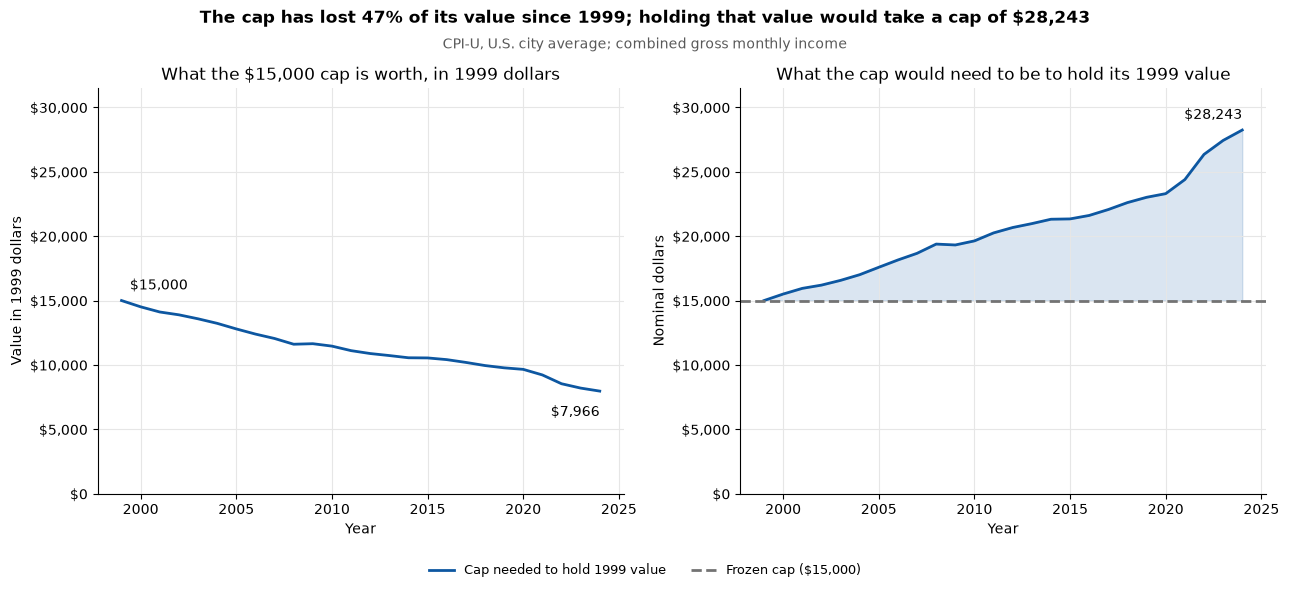

In [11]:
# CPI ratio to the base year, for each year
cpi_ratio = cpi_wide_df[CPI_SERIES_US] / cpi_wide_df.loc[BASE_YEAR, CPI_SERIES_US]
# The cap's value in base-year dollars, and the nominal cap needed to hold 1999 value
real_cap = INCOME_CAP / cpi_ratio
cap_to_hold_value = INCOME_CAP * cpi_ratio

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(13, 5))

# Left: the frozen cap, measured in 1999 dollars
ax_left.plot(real_cap.index, real_cap.values, color=plt.cm.Blues(0.85), linewidth=2)
# Start label sits above and right of the first point; end label sits below the last
ax_left.annotate(f"${real_cap[BASE_YEAR]:,.0f}", (BASE_YEAR, real_cap[BASE_YEAR]),
                 textcoords="offset points", xytext=(6, 8), ha="left")
ax_left.annotate(f"${real_cap[CURRENT_YEAR]:,.0f}", (CURRENT_YEAR, real_cap[CURRENT_YEAR]),
                 textcoords="offset points", xytext=(0, -10), ha="right", va="top")
ax_left.set_ylim(0, INCOME_CAP * 2.1)
ax_left.set_ylabel(f"Value in {BASE_YEAR} dollars")
ax_left.set_title(f"What the $15,000 cap is worth, in {BASE_YEAR} dollars")

# Right: the nominal cap needed to hold 1999 value, against the frozen cap
ax_right.plot(cap_to_hold_value.index, cap_to_hold_value.values, color=plt.cm.Blues(0.85),
              linewidth=2, label=f"Cap needed to hold {BASE_YEAR} value")
ax_right.axhline(INCOME_CAP, color="0.45", linewidth=2, linestyle="--",
                 label="Frozen cap ($15,000)")
ax_right.fill_between(cap_to_hold_value.index, INCOME_CAP, cap_to_hold_value.values,
                      color=plt.cm.Blues(0.85), alpha=0.15)
ax_right.annotate(f"${cap_to_hold_value[CURRENT_YEAR]:,.0f}",
                  (CURRENT_YEAR, cap_to_hold_value[CURRENT_YEAR]),
                  textcoords="offset points", xytext=(0, 8), ha="right")
ax_right.set_ylim(0, INCOME_CAP * 2.1)
ax_right.set_ylabel("Nominal dollars")
ax_right.set_title(f"What the cap would need to be to hold its {BASE_YEAR} value")

# Shared formatting
for ax in [ax_left, ax_right]:
    ax.set_xlabel("Year")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.grid(color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
add_legend_below(fig, ax_right)
add_figure_titles(fig, f"The cap has lost {1 - 1 / DEFLATOR_US:.0%} of its value since "
                  f"{BASE_YEAR}; holding that value would take a cap of "
                  f"{dollars(cap_to_hold_value[CURRENT_YEAR])}",
                  "CPI-U, U.S. city average; combined gross monthly income")
plt.show()

## 4. Oklahoma families in the microdata

Families are married couples living with at least one own child under 18, from the 2000 Census
(1999 income) and the 2024 ACS through IPUMS,[^ipums] weighted by person weights (17,249 family
records for 1999 and 2,935 for 2024). Both parents' incomes are observed in one household, so these
couples stand in for separated parents (see Limitations). Each family is matched to its schedule
row by combined monthly income; families above the cap get the \$15,000 row, the starting point
under § 119(B).

In [12]:
#| include: false
# Load the IPUMS extract (pandas reads the .gz file directly)
ipums_df = pd.read_csv(IPUMS_FILE)

# IPUMS "not applicable" code for total personal income
INCTOT_NA_CODE = 9999999
# Group quarters codes: 1, 2, and 5 are households; 3 and 4 are group quarters
HOUSEHOLD_GQ_CODES = [1, 2, 5]

# Keep people living in households, not group quarters
people_df = ipums_df[ipums_df["GQ"].isin(HOUSEHOLD_GQ_CODES)].copy()

# Recode "not applicable" income to missing
people_df["INCTOT"] = people_df["INCTOT"].replace(INCTOT_NA_CODE, np.nan)

print(f"People in households: {len(people_df):,} of {len(ipums_df):,}")
print(people_df.groupby("YEAR").size())

People in households: 205,046 of 213,062
YEAR
2000    168213
2024     36833
dtype: int64


In [13]:
#| include: false
HOUSEHOLD_KEYS = ["SAMPLE", "SERIAL"]


def build_couple_families(people_df):
    """Build one row per married couple with at least one own child under 18."""
    # One row per couple: keep the spouse with the lower person number
    first_spouse_df = people_df[(people_df["SPLOC"] > 0)
                                & (people_df["PERNUM"] < people_df["SPLOC"])]
    couples_df = first_spouse_df[HOUSEHOLD_KEYS + ["YEAR", "PERNUM", "SPLOC", "PERWT", "INCTOT"]]
    couples_df = couples_df.rename(columns={"PERNUM": "pernum_a", "SPLOC": "pernum_b",
                                            "INCTOT": "income_a"})

    # Attach the other spouse's income
    spouse_income_df = people_df[HOUSEHOLD_KEYS + ["PERNUM", "INCTOT"]].rename(
        columns={"PERNUM": "pernum_b", "INCTOT": "income_b"})
    couples_df = couples_df.merge(spouse_income_df, on=HOUSEHOLD_KEYS + ["pernum_b"],
                                  how="left")
    couples_df["couple_id"] = np.arange(len(couples_df))

    # Children under 18, one row per child and linked parent
    kids_df = people_df[people_df["AGE"] < 18]
    kid_parents_df = kids_df.melt(id_vars=HOUSEHOLD_KEYS + ["PERNUM"],
                                  value_vars=["MOMLOC", "POPLOC"], value_name="parent_pernum")
    kid_parents_df = kid_parents_df[kid_parents_df["parent_pernum"] > 0]

    # Couple members, one row per spouse
    members_df = couples_df.melt(id_vars=HOUSEHOLD_KEYS + ["couple_id"],
                                 value_vars=["pernum_a", "pernum_b"],
                                 value_name="parent_pernum")

    # Count each child once per couple, whether linked to one spouse or both
    child_counts = (members_df.merge(kid_parents_df, on=HOUSEHOLD_KEYS + ["parent_pernum"])
                    .groupby("couple_id")["PERNUM"].nunique()
                    .rename("n_children_actual"))
    # Inner merge keeps only couples with at least one child under 18
    couples_df = couples_df.merge(child_counts, on="couple_id", how="inner")

    # Combined monthly parental income (missing if either spouse's income is missing)
    couples_df["combined_monthly_income"] = (
        couples_df[["income_a", "income_b"]].sum(axis=1, min_count=2) / 12)
    # The schedule's last column covers six or more children
    couples_df["n_children"] = couples_df["n_children_actual"].clip(upper=6)
    return couples_df.rename(columns={"PERWT": "weight"})


families_df = build_couple_families(people_df)
print(f"Married-couple families with children under 18: {len(families_df):,}")
print(families_df.groupby("YEAR")["weight"].agg(["size", "sum"]))

Married-couple families with children under 18: 20,361
       size       sum
YEAR                 
2000  17399  348783.0
2024   2962  336079.0


In [14]:
#| include: false
def assign_schedule(families_df, income_column):
    """Look up the presumptive schedule amount for each family's income and child count."""
    lookup_df = families_df[[income_column, "n_children"]].copy()
    # Above the cap, the starting point is the 15,000 row (43 O.S. § 119(B))
    lookup_df["lookup_income"] = lookup_df[income_column].clip(upper=INCOME_CAP)
    lookup_df["row_id"] = lookup_df.index
    lookup_df = lookup_df.sort_values("lookup_income")

    schedule_df = schedule_long_df[["combined_monthly_income", "n_children",
                                    "total_support_amount"]].copy()
    schedule_df["combined_monthly_income"] = schedule_df["combined_monthly_income"].astype(float)
    schedule_df = schedule_df.sort_values("combined_monthly_income")

    # "Equal to or above": take the highest schedule row at or below the family's income
    matched_df = pd.merge_asof(lookup_df, schedule_df, left_on="lookup_income",
                               right_on="combined_monthly_income", by="n_children",
                               direction="backward")
    return matched_df.set_index("row_id")["total_support_amount"].reindex(families_df.index)


families_df["support_amount"] = assign_schedule(families_df, "combined_monthly_income")
families_df["support_share"] = (families_df["support_amount"]
                                / families_df["combined_monthly_income"])
families_df["above_cap"] = families_df["combined_monthly_income"] > INCOME_CAP

# Save for Part 5
families_df.to_csv(DATA_PROCESSED_DIR / "families_married.csv", index=False)

# Families below the schedule's first row (zero or negative income) get no schedule amount
no_amount = families_df["support_amount"].isna()
print(f"Families with no schedule amount (combined income below 50 dollars a month): "
      f"{no_amount.sum():,} of {len(families_df):,} records")

# Weight carried only by families above the cap, for the weighted share
families_df["weight_above_cap"] = families_df["weight"].where(families_df["above_cap"], 0)

# Summarize families above the cap by sample year
cap_summary_df = families_df.groupby("YEAR").agg(
    family_records=("above_cap", "size"),
    records_above_cap=("above_cap", "sum"),
    share_unweighted=("above_cap", "mean"),
    weight_total=("weight", "sum"),
    weight_above_cap=("weight_above_cap", "sum"),
)
cap_summary_df["share_weighted"] = (cap_summary_df["weight_above_cap"]
                                    / cap_summary_df["weight_total"])

# Readable labels; the 2000 sample reports 1999 income
cap_summary_df = cap_summary_df[["family_records", "records_above_cap",
                                 "share_unweighted", "share_weighted"]]
cap_summary_df.columns = ["Family records", "Records above cap",
                          "Share above cap (unweighted)", "Share above cap (weighted)"]
cap_summary_df.index = cap_summary_df.index.map({2000: "2000 Census (1999 income)",
                                                 2024: "2024 ACS"})
cap_summary_df.index.name = None

print("Married-couple families with children under 18: combined income above the "
      "15,000-dollar monthly cap")
display(cap_summary_df.style.format({
    "Family records": "{:,.0f}",
    "Records above cap": "{:,.0f}",
    "Share above cap (unweighted)": "{:.1%}",
    "Share above cap (weighted)": "{:.1%}",
}))

Families with no schedule amount (combined income below 50 dollars a month): 171 of 20,361 records
Married-couple families with children under 18: combined income above the 15,000-dollar monthly cap


,Family records,Records above cap,Share above cap (unweighted),Share above cap (weighted)
2000 Census (1999 income),"17,399",288,1.7%,2.1%
2024 ACS,"2,962",359,12.1%,13.5%


## 5. Analysis

### Who the schedule covers

In 1999 the cap sat at the 98th percentile of combined income for married parents in Oklahoma, and
about one family in 50 (2.1%) earned above it. By 2024 it sat at the 86th percentile, and
one family in 7 (13.6%; 95% interval 12.1% to 15.4%)[^bootstrap] earned above it.
Indexed to prices, the cap would leave 3.9% above it. Past the cap, § 119(B) makes the
\$15,000 row a starting point and leaves the rest to the court. Even across states' written
guidelines, outcomes vary most for high-income cases,[^bartfeld] and every judge exercises
discretion differently, so the order becomes a gamble for obligors and payees alike, and children
lose the stability of a predictable amount. That uncertainty may also shift how often families
mediate rather than litigate, which this data cannot observe.

In [15]:
# Low-income phase-in: incomes where the one-child share is still rising
PHASE_IN_MAX = 1000


def weighted_quantile(values, weights, quantiles):
    """Return weighted quantiles of values, interpolating between observations."""
    order = np.argsort(values)
    sorted_values = np.asarray(values)[order]
    sorted_weights = np.asarray(weights)[order]
    # Cumulative weight at the midpoint of each observation, scaled to 0 to 1
    cumulative = (np.cumsum(sorted_weights) - 0.5 * sorted_weights) / sorted_weights.sum()
    return np.interp(quantiles, cumulative, sorted_values)


# Analysis sample, used by every result below: families with a schedule amount under both
# the frozen schedule and the price-indexed schedule (Part 5). Incomes below the first row
# (50 dollars a month, or about 94 in 2024 dollars once indexed) have no schedule amount.
has_frozen_amount = families_df["support_amount"].notna()
below_indexed_first_row = ((families_df["YEAR"] == 2024)
                           & (families_df["combined_monthly_income"] < 50 * DEFLATOR_US))
analysis_df = families_df[has_frozen_amount & ~below_indexed_first_row].copy()
print(f"Analysis sample: {len(analysis_df):,} of {len(families_df):,} family records "
      f"({(~has_frozen_amount).sum():,} with no frozen-schedule amount; "
      f"{(has_frozen_amount & below_indexed_first_row).sum():,} more with no indexed amount)")


def coverage_summary(group_df):
    """Weighted shares of families above the cap and in the phase-in range."""
    weights = group_df["weight"]
    income = group_df["combined_monthly_income"]
    in_phase_in = income < PHASE_IN_MAX
    return pd.Series({
        "records": len(group_df),
        "weighted_families": weights.sum(),
        "share_above_cap": weights[group_df["above_cap"]].sum() / weights.sum(),
        "records_above_cap": group_df["above_cap"].sum(),
        "share_in_phase_in": weights[in_phase_in].sum() / weights.sum(),
        "records_in_phase_in": in_phase_in.sum(),
    })


coverage_df = pd.DataFrame({year: coverage_summary(group_df)
                            for year, group_df in analysis_df.groupby("YEAR")}).T

# Readable labels for display
coverage_display_df = coverage_df.copy()
coverage_display_df.columns = ["Family records", "Weighted families",
                               "Share above cap", "Records above cap",
                               "Share in phase-in (below 1,000/mo)", "Records in phase-in"]
coverage_display_df.index = coverage_display_df.index.map({2000: "2000 Census (1999 income)",
                                                           2024: "2024 ACS"})
print("Married-couple families with children under 18 and positive combined income")
display(coverage_display_df.style.format({
    "Family records": "{:,.0f}",
    "Weighted families": "{:,.0f}",
    "Share above cap": "{:.1%}",
    "Records above cap": "{:,.0f}",
    "Share in phase-in (below 1,000/mo)": "{:.1%}",
    "Records in phase-in": "{:,.0f}",
}))

Analysis sample: 20,184 of 20,361 family records (171 with no frozen-schedule amount; 6 more with no indexed amount)
Married-couple families with children under 18 and positive combined income


,Family records,Weighted families,Share above cap,Records above cap,"Share in phase-in (below 1,000/mo)",Records in phase-in
2000 Census (1999 income),"17,249","345,938",2.1%,288,4.4%,818
2024 ACS,"2,935","332,531",13.6%,359,1.5%,52


In [16]:
PERCENTILES = np.arange(1, 100)
income_by_year = {
    year: weighted_quantile(group_df["combined_monthly_income"], group_df["weight"],
                            PERCENTILES / 100)
    for year, group_df in analysis_df.groupby("YEAR")
}
percentiles_df = pd.DataFrame({"percentile": PERCENTILES,
                               "income_1999": income_by_year[2000],
                               "income_2024": income_by_year[2024]})
percentiles_df["growth"] = percentiles_df["income_2024"] / percentiles_df["income_1999"]
percentiles_df.to_csv(DATA_PROCESSED_DIR / "income_percentiles.csv", index=False)

# Percentile at the cap in each year
cap_pct_1999 = np.interp(INCOME_CAP, percentiles_df["income_1999"], PERCENTILES)
cap_pct_2024 = np.interp(INCOME_CAP, percentiles_df["income_2024"], PERCENTILES)

# Readable display of selected percentiles
selected_df = percentiles_df[percentiles_df["percentile"].isin([10, 25, 50, 75, 90, 95])]
percentile_display_df = pd.DataFrame({
    "Percentile": selected_df["percentile"],
    "1999 combined monthly income": selected_df["income_1999"],
    "2024 combined monthly income": selected_df["income_2024"],
    "Income growth (2024 / 1999)": selected_df["growth"],
    "Growth relative to prices": selected_df["growth"] / DEFLATOR_US - 1,
})
print("Weighted income percentiles, married-couple families with children under 18 "
      "(nominal dollars)")
display(percentile_display_df.style.hide(axis="index").format({
    "1999 combined monthly income": "${:,.0f}",
    "2024 combined monthly income": "${:,.0f}",
    "Income growth (2024 / 1999)": "{:.2f}x",
    "Growth relative to prices": "{:+.0%}",
}))
print(f"Prices grew {DEFLATOR_US:.3f}x over the same period (CPI-U).")
print(f"The 15,000-dollar cap sits at about the {cap_pct_1999:.0f}th percentile in 1999 "
      f"and the {cap_pct_2024:.0f}th in 2024.")

Weighted income percentiles, married-couple families with children under 18 (nominal dollars)


Percentile,1999 combined monthly income,2024 combined monthly income,Income growth (2024 / 1999),Growth relative to prices
10,"$1,467","$2,917",1.99x,+6%
25,"$2,350","$5,000",2.13x,+13%
50,"$3,750","$7,917",2.11x,+12%
75,"$5,467","$11,833",2.16x,+15%
90,"$7,854","$17,167",2.19x,+16%
95,"$10,042","$23,665",2.36x,+25%


Prices grew 1.883x over the same period (CPI-U).
The 15,000-dollar cap sits at about the 98th percentile in 1999 and the 86th in 2024.


### The share of income assigned

The 1999 schedule weighed the cost of raising children against what parents could pay: the share
assigned ramps up briefly at the lowest incomes, then declines as income rises. To see what the
freeze did, compare families at the same place in each year's income distribution, such as the
family in the middle in 1999 and the family in the middle in 2024. At the same percentile, the
schedule now assigns about a fifth less of combined income (21% on average; 95%
interval 20% to 22%). The median one-child family fell from 15.0% to 11.3%. Only about 17% of that decline comes from families above the 2024 cap. Most of it happens inside the
table, so raising the cap alone would not restore 1999 shares. The loss is also uneven: real
income grew 6% at the 10th percentile and 25% at the 95th,[^growth] so higher earners
slid further down the curve, deepening a regressivity earlier work documented, in which
lower-income parents are ordered to pay a larger share of their income.[^stirling]

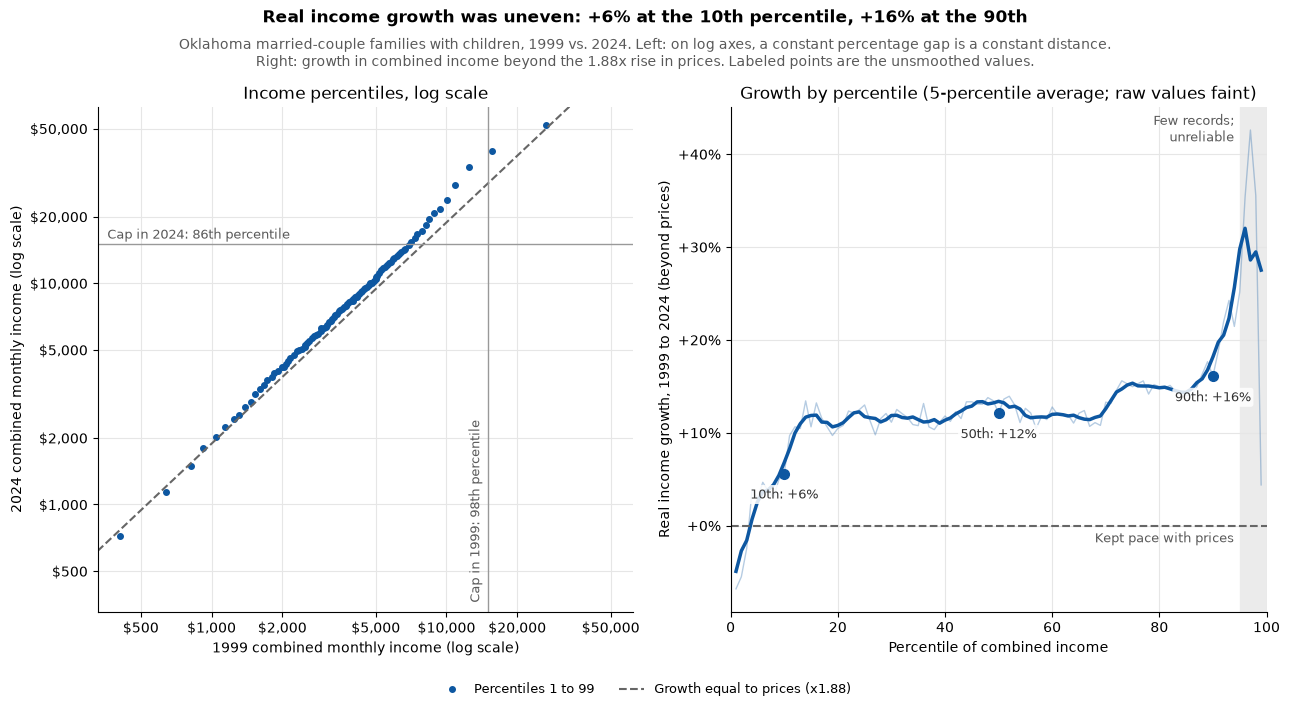

In [17]:
# Uneven income growth, two views: a log-scale Q-Q plot and real growth by percentile
real_growth = percentiles_df["growth"] / DEFLATOR_US - 1
# Five-percentile rolling average smooths income heaping and sampling noise
real_growth_smooth = real_growth.rolling(5, center=True, min_periods=3).mean()
UNRELIABLE_TOP = 95  # percentiles above this rest on few 2024 records
LOG_TICKS = [500, 1000, 2000, 5000, 10000, 20000, 50000]

fig, (ax_qq, ax_growth) = plt.subplots(1, 2, figsize=(13, 6))

# Left: Q-Q plot on log axes, where proportional growth is a straight line
ax_qq.plot(percentiles_df["income_1999"], percentiles_df["income_2024"], "o",
           color=plt.cm.Blues(0.85), markersize=4, label="Percentiles 1 to 99")
log_min = percentiles_df["income_1999"].min() * 0.8
log_max = percentiles_df["income_2024"].max() * 1.2
reference_x = np.array([log_min, log_max])
ax_qq.plot(reference_x, reference_x * DEFLATOR_US, color="0.4", linestyle="--",
           linewidth=1.5, label=f"Growth equal to prices (x{DEFLATOR_US:.2f})")
ax_qq.axvline(INCOME_CAP, color="0.6", linewidth=1)
ax_qq.axhline(INCOME_CAP, color="0.6", linewidth=1)
ax_qq.annotate(f"Cap in 2024: {ordinal(cap_pct_2024)} percentile", (log_min * 1.1, INCOME_CAP),
               xytext=(0, 4), textcoords="offset points", fontsize=9, color="0.35")
ax_qq.annotate(f"Cap in 1999: {ordinal(cap_pct_1999)} percentile", (INCOME_CAP, log_min * 1.1),
               xytext=(-4, 0), textcoords="offset points", rotation=90, ha="right",
               va="bottom", fontsize=9, color="0.35")
ax_qq.set_xscale("log")
ax_qq.set_yscale("log")
ax_qq.set_xlim(log_min, log_max)
ax_qq.set_ylim(log_min, log_max)
for axis in [ax_qq.xaxis, ax_qq.yaxis]:
    axis.set_major_locator(plt.FixedLocator(LOG_TICKS))
    axis.set_minor_locator(plt.NullLocator())
    axis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax_qq.set_xlabel("1999 combined monthly income (log scale)")
ax_qq.set_ylabel("2024 combined monthly income (log scale)")
ax_qq.set_title("Income percentiles, log scale")

# Right: real growth at each percentile; zero means income kept pace with prices
ax_growth.axvspan(UNRELIABLE_TOP, 100, color="0.92", zorder=0)
ax_growth.annotate("Few records;\nunreliable", (UNRELIABLE_TOP, 1),
                   xycoords=("data", "axes fraction"), xytext=(-4, -4),
                   textcoords="offset points", ha="right", va="top", fontsize=9, color="0.35")
ax_growth.plot(percentiles_df["percentile"], real_growth, color=plt.cm.Blues(0.85),
               linewidth=1, alpha=0.3)
ax_growth.plot(percentiles_df["percentile"], real_growth_smooth, color=plt.cm.Blues(0.85),
               linewidth=2.5)
ax_growth.axhline(0, color="0.4", linestyle="--", linewidth=1.5)
ax_growth.annotate("Kept pace with prices", (UNRELIABLE_TOP, 0), xytext=(-4, -12),
                   textcoords="offset points", ha="right", fontsize=9, color="0.35")
# Labeled points use the raw values, so they match the percentile table exactly
for percentile in [10, 50, 90]:
    row = percentiles_df["percentile"] == percentile
    point_value = real_growth[row].iloc[0]
    ax_growth.plot(percentile, point_value, "o", color=plt.cm.Blues(0.85), markersize=7,
                   zorder=4)
    ax_growth.annotate(f"{ordinal(percentile)}: {point_value:+.0%}", (percentile, point_value),
                       xytext=(0, -18), textcoords="offset points", ha="center", fontsize=9,
                       color="0.2", zorder=5,
                       bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "alpha": 0.85,
                             "edgecolor": "none"})
ax_growth.set_xlabel("Percentile of combined income")
ax_growth.set_ylabel("Real income growth, 1999 to 2024 (beyond prices)")
ax_growth.set_title("Growth by percentile (5-percentile average; raw values faint)")
ax_growth.set_xlim(0, 100)
ax_growth.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:+.0%}"))

for ax in [ax_qq, ax_growth]:
    ax.grid(color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

growth_10 = real_growth[percentiles_df["percentile"] == 10].iloc[0]
growth_90 = real_growth[percentiles_df["percentile"] == 90].iloc[0]
fig.tight_layout()
add_legend_below(fig, ax_qq)
add_figure_titles(fig, f"Real income growth was uneven: {growth_10:+.0%} at the 10th "
                  f"percentile, {growth_90:+.0%} at the 90th",
                  "Oklahoma married-couple families with children, 1999 vs. 2024. "
                  "Left: on log axes, a constant percentage gap is a constant distance.\n"
                  "Right: growth in combined income beyond the 1.88x rise in prices. "
                  "Labeled points are the unsmoothed values.")
plt.show()

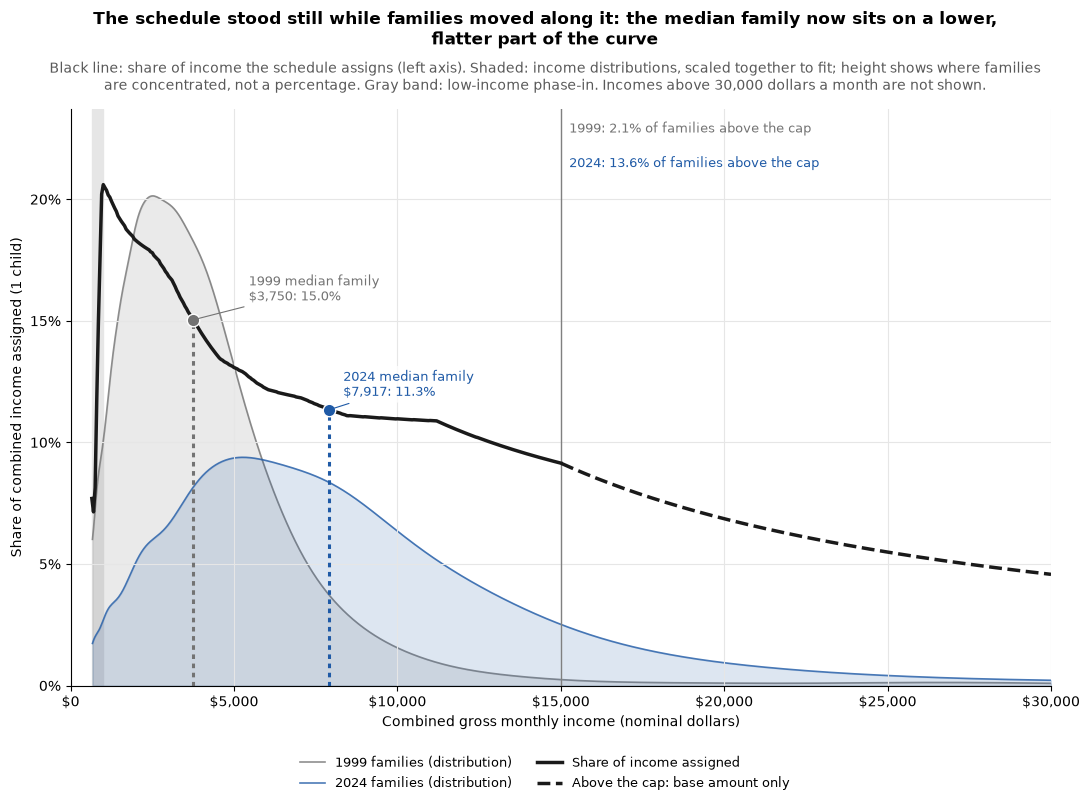

In [18]:
# The schedule's share curve over the income distributions it is applied to, on one panel.
# The share curve owns the vertical axis. Both income distributions are scaled by one common
# factor to sit behind it, so they compare truly with each other but have no numeric scale.
CURVE_CHILDREN = 1
INCOME_AXIS_MAX = 30000
DISTRIBUTION_HEIGHT = 0.85  # tallest distribution peak, as a fraction of the axis height
income_grid = np.linspace(1, INCOME_AXIS_MAX, 900)
DISTRIBUTION_STYLES = {
    2000: {"label": "1999", "color": "0.45", "year": BASE_YEAR, "label_offset": (40, 14)},
    2024: {"label": "2024", "color": "#1f5aa6", "year": CURRENT_YEAR, "label_offset": (10, 10)},
}

# Within the schedule, plot the schedule's own rows (no lookup steps on a fine grid)
schedule_rows = schedule_long_df[(schedule_long_df["n_children"] == CURVE_CHILDREN)
                                 & (schedule_long_df["combined_monthly_income"]
                                    >= PHASE_IN_START)]
# Above the cap, the base amount only, as a share of a rising income
above_cap_income = income_grid[income_grid > INCOME_CAP]
cap_amount = schedule_rows["total_support_amount"].iloc[-1]
above_cap_share = cap_amount / above_cap_income
axis_top = schedule_rows["support_share"].max() * 1.15

# Weighted income densities for each year, fit on log income so the long upper tail does
# not widen the smoothing and spread families toward zero; then converted back to dollars.
# One shared scale factor keeps the two years comparable.
densities = {}
for sample_year in DISTRIBUTION_STYLES:
    year_df = analysis_df[analysis_df["YEAR"] == sample_year]
    log_kde = gaussian_kde(np.log(year_df["combined_monthly_income"]),
                           weights=year_df["weight"])
    densities[sample_year] = log_kde(np.log(income_grid)) / income_grid
    # Blank below the phase-in start: the share curve does not exist there, and the
    # conversion from log income produces spikes near zero
    densities[sample_year][income_grid < PHASE_IN_START] = np.nan
common_scale = DISTRIBUTION_HEIGHT * axis_top / max(np.nanmax(d) for d in densities.values())

fig, ax = plt.subplots(figsize=(11, 6.5))

# Backdrop: the two income distributions, scaled together
for sample_year, style in DISTRIBUTION_STYLES.items():
    scaled_density = densities[sample_year] * common_scale
    ax.fill_between(income_grid, scaled_density, color=style["color"], alpha=0.15, zorder=1)
    ax.plot(income_grid, scaled_density, color=style["color"], linewidth=1.2, alpha=0.8,
            zorder=1, label=f"{style['label']} families (distribution)")

# Foreground: the schedule's share curve
ax.plot(schedule_rows["combined_monthly_income"], schedule_rows["support_share"],
        color="0.1", linewidth=2.5, zorder=3, label="Share of income assigned")
ax.plot(above_cap_income, above_cap_share, color="0.1", linewidth=2.5, linestyle="--",
        zorder=3, label="Above the cap: base amount only")

# Median family in each year: dotted line up to its point on the curve
for sample_year, style in DISTRIBUTION_STYLES.items():
    year_df = analysis_df[analysis_df["YEAR"] == sample_year]
    median_income = weighted_quantile(year_df["combined_monthly_income"], year_df["weight"], 0.5)
    median_df = pd.DataFrame({"income": [median_income], "n_children": CURVE_CHILDREN})
    median_share = assign_schedule(median_df, "income").iloc[0] / median_income
    ax.plot([median_income, median_income], [0, median_share], color=style["color"],
            linestyle=(0, (1.5, 1.5)), linewidth=2.2, zorder=2)
    ax.plot(median_income, median_share, "o", color=style["color"], markersize=9, zorder=4,
            markeredgecolor="white", markeredgewidth=1)
    # Per-year label offset, leader line, and a light background
    ax.annotate(f"{style['year']} median family\n{dollars(median_income)}: "
                f"{median_share:.1%}", (median_income, median_share),
                xytext=style["label_offset"], textcoords="offset points", fontsize=9,
                color=style["color"], zorder=4,
                bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "alpha": 0.8,
                      "edgecolor": "none"},
                arrowprops={"arrowstyle": "-", "color": style["color"], "linewidth": 0.8})

# The phase-in band and the cap, with the share of families above the cap
ax.axvspan(PHASE_IN_START, peak_income, color="0.9", zorder=0)
ax.axvline(INCOME_CAP, color="0.5", linewidth=1, zorder=2)
for row, (sample_year, style) in enumerate(DISTRIBUTION_STYLES.items()):
    share_above = coverage_df.loc[sample_year, "share_above_cap"]
    ax.annotate(f"{style['year']}: {share_above:.1%} of families above the cap",
                (INCOME_CAP, 0.96 - 0.06 * row), xycoords=("data", "axes fraction"),
                xytext=(6, 0), textcoords="offset points", fontsize=9, color=style["color"])

child_word = "child" if CURVE_CHILDREN == 1 else "children"
ax.set_ylabel(f"Share of combined income assigned ({CURVE_CHILDREN} {child_word})")
ax.set_ylim(0, axis_top)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.set_xlabel("Combined gross monthly income (nominal dollars)")
ax.set_xlim(0, INCOME_AXIS_MAX)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax.grid(color="0.9", linewidth=0.8, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
add_legend_below(fig, ax)
add_figure_titles(fig, "The schedule stood still while families moved along it: the median "
                  "family now sits on a lower, flatter part of the curve",
                  "Black line: share of income the schedule assigns (left axis). Shaded: income "
                  "distributions, scaled together to fit; height shows where families\n"
                  "are concentrated, not a percentage. Gray band: low-income phase-in. Incomes "
                  f"above {INCOME_AXIS_MAX:,} dollars a month are not shown.")
plt.show()

In [19]:
#| include: false
CHILD_SCENARIOS = [1, 2]
share_rows = []
for n_children in CHILD_SCENARIOS:
    for year, income_column in [(BASE_YEAR, "income_1999"), (CURRENT_YEAR, "income_2024")]:
        lookup_df = pd.DataFrame({"income": percentiles_df[income_column],
                                  "n_children": n_children})
        support = assign_schedule(lookup_df, "income")
        share_rows.append(pd.DataFrame({"percentile": PERCENTILES, "n_children": n_children,
                                        "year": year,
                                        "share": support / lookup_df["income"]}))
share_by_pct_df = pd.concat(share_rows).pivot_table(index=["n_children", "percentile"],
                                                    columns="year",
                                                    values="share").reset_index()
share_by_pct_df["change_points"] = (share_by_pct_df[CURRENT_YEAR]
                                    - share_by_pct_df[BASE_YEAR]) * 100

# Readable display of selected percentiles
selected_df = share_by_pct_df[share_by_pct_df["percentile"].isin([10, 25, 50, 75, 90])]
share_display_df = pd.DataFrame({
    "Children": selected_df["n_children"],
    "Percentile": selected_df["percentile"],
    "Share assigned, 1999": selected_df[BASE_YEAR],
    "Share assigned, 2024": selected_df[CURRENT_YEAR],
    "Change (percentage points)": selected_df["change_points"],
    "Relative change": selected_df[CURRENT_YEAR] / selected_df[BASE_YEAR] - 1,
})
print("Presumptive support as a share of combined income, at the same income percentile "
      "in each year")
display(share_display_df.style.hide(axis="index").format({
    "Share assigned, 1999": "{:.1%}",
    "Share assigned, 2024": "{:.1%}",
    "Change (percentage points)": "{:+.1f}",
    "Relative change": "{:+.0%}",
}))

Presumptive support as a share of combined income, at the same income percentile in each year


Children,Percentile,"Share assigned, 1999","Share assigned, 2024",Change (percentage points),Relative change
1,10,19.1%,16.9%,-2.2,-11%
1,25,18.0%,13.1%,-4.9,-27%
1,50,15.0%,11.3%,-3.7,-25%
1,75,12.7%,10.5%,-2.2,-17%
1,90,11.4%,8.0%,-3.4,-30%
2,10,27.8%,24.5%,-3.3,-12%
2,25,26.0%,18.9%,-7.1,-27%
2,50,21.7%,16.3%,-5.4,-25%
2,75,18.2%,14.6%,-3.7,-20%
2,90,16.4%,11.4%,-5.0,-30%


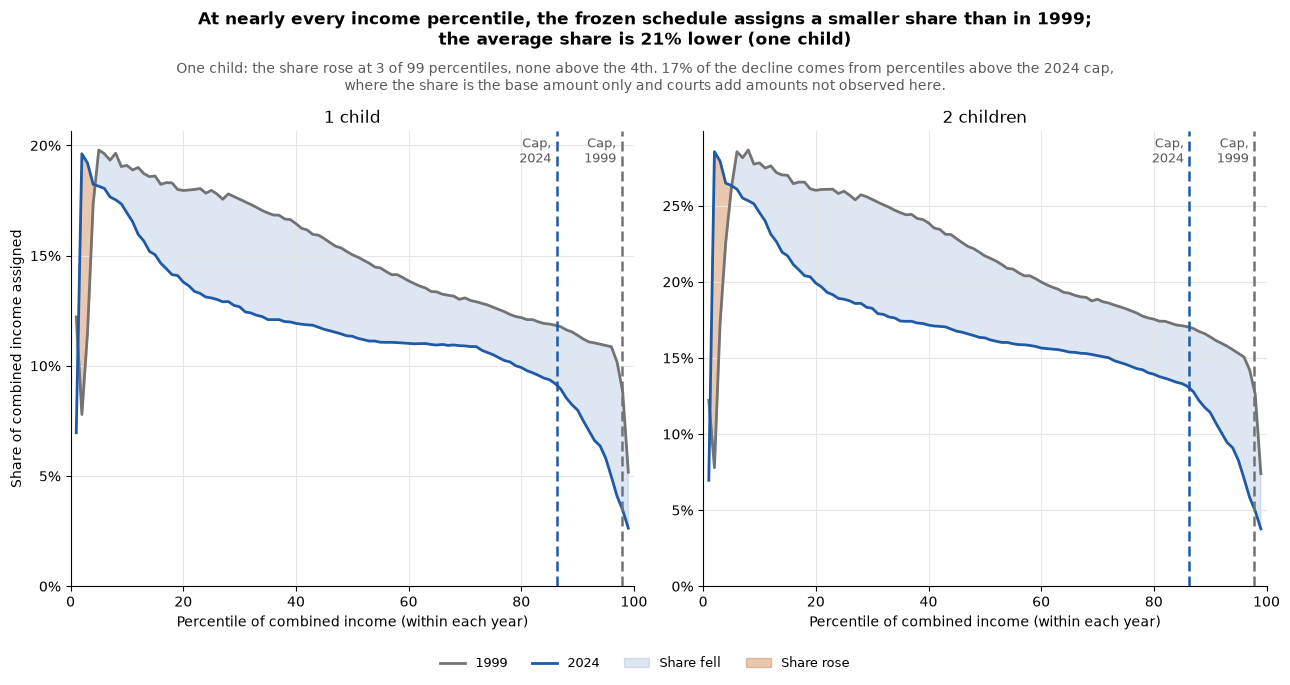

In [20]:
# Share assigned at each income percentile, 1999 and 2024, with the change shaded
COLOR_1999_LINE = "0.45"
COLOR_2024_LINE = "#1f5aa6"
COLOR_SHARE_UP = "#c0631a"

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
percentiles_up = {}
highest_up = {}
average_change = {}
decline_above_cap = {}
for ax, n_children in zip(axes, CHILD_SCENARIOS):
    child_df = share_by_pct_df[share_by_pct_df["n_children"] == n_children]
    share_1999 = child_df[BASE_YEAR].to_numpy()
    share_2024 = child_df[CURRENT_YEAR].to_numpy()
    rose = share_2024 > share_1999
    average_change[n_children] = share_2024.mean() / share_1999.mean() - 1
    # Part of the average change from percentiles above the 2024 cap (base amount only)
    change = share_2024 - share_1999
    decline_above_cap[n_children] = (change[PERCENTILES >= cap_pct_2024].sum()
                                     / change.sum())
    percentiles_up[n_children] = int(rose.sum())
    highest_up[n_children] = int(PERCENTILES[rose].max()) if rose.any() else 0

    ax.plot(PERCENTILES, share_1999, color=COLOR_1999_LINE, linewidth=2, label="1999")
    ax.plot(PERCENTILES, share_2024, color=COLOR_2024_LINE, linewidth=2, label="2024")
    # Shade the gap: blue where the share fell, orange where it rose
    ax.fill_between(PERCENTILES, share_1999, share_2024, where=share_2024 <= share_1999,
                    color=COLOR_2024_LINE, alpha=0.15, interpolate=True,
                    label="Share fell")
    ax.fill_between(PERCENTILES, share_1999, share_2024, where=share_2024 > share_1999,
                    color=COLOR_SHARE_UP, alpha=0.35, interpolate=True,
                    label="Share rose")

    # The cap's percentile in each year; above it the share is the base amount only
    for cap_pct, year_label, cap_color in [(cap_pct_2024, CURRENT_YEAR, COLOR_2024_LINE),
                                           (cap_pct_1999, BASE_YEAR, COLOR_1999_LINE)]:
        # Bolder dashed line, colored to match its year's curve
        ax.axvline(cap_pct, color=cap_color, linestyle=(0, (4, 2)), linewidth=1.8,
                   zorder=4)
        ax.annotate(f"Cap,\n{year_label}", (cap_pct, 1), xycoords=("data", "axes fraction"),
                    xytext=(-4, -4), textcoords="offset points", ha="right", va="top",
                    fontsize=9, color="0.35")

    child_word = "child" if n_children == 1 else "children"
    ax.set_title(f"{n_children} {child_word}")
    ax.set_xlabel("Percentile of combined income (within each year)")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, None)
    # Ticks every 5 points so the whole-percent labels are exact
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    ax.grid(color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Share of combined income assigned")
fig.tight_layout()
add_legend_below(fig, axes[0], ncol=4)
direction = "lower" if average_change[1] < 0 else "higher"
add_figure_titles(fig, "At nearly every income percentile, the frozen schedule assigns a "
                  f"smaller share than in 1999; the average share is "
                  f"{abs(average_change[1]):.0%} {direction} (one child)",
                  f"One child: the share rose at {percentiles_up[1]} of 99 percentiles, "
                  f"none above the {ordinal(highest_up[1])}. {decline_above_cap[1]:.0%} of the "
                  "decline comes from percentiles above the 2024 cap,\nwhere the share is the "
                  "base amount only and courts add amounts not observed here.")
plt.show()

In [21]:
# Quantify the shaded area in the percentile chart. Each percentile holds 1% of families,
# so a curve's average across percentiles is the average share assigned to families, and
# the area between the curves is the average change in share, in percentage points.


def region_contribution(change, region):
    """Contribution of one region of percentiles to the average change, in points."""
    return change[region].sum() / len(change) * 100


area_rows = []
for n_children in CHILD_SCENARIOS:
    child_df = share_by_pct_df[share_by_pct_df["n_children"] == n_children]
    percentiles = child_df["percentile"].to_numpy()
    share_1999 = child_df[BASE_YEAR].to_numpy()
    share_2024 = child_df[CURRENT_YEAR].to_numpy()
    change = share_2024 - share_1999

    # Regions of the percentile axis, split at each year's cap
    below_2024_cap = percentiles < cap_pct_2024
    between_caps = (percentiles >= cap_pct_2024) & (percentiles <= cap_pct_1999)
    above_1999_cap = percentiles > cap_pct_1999

    area_rows.append({
        "Children": n_children,
        "Average share, 1999": share_1999.mean(),
        "Average share, 2024": share_2024.mean(),
        "Relative change": share_2024.mean() / share_1999.mean() - 1,
        "Net area (points)": change.mean() * 100,
        "Area where share fell": region_contribution(change, change < 0),
        "Area where share rose": region_contribution(change, change > 0),
        "From below the 2024 cap": region_contribution(change, below_2024_cap),
        "From between the caps": region_contribution(change, between_caps),
        "From above the 1999 cap": region_contribution(change, above_1999_cap),
    })

area_df = pd.DataFrame(area_rows)
area_df.to_csv(DATA_PROCESSED_DIR / "share_area_by_percentile.csv", index=False)
print("Area between the 1999 and 2024 share curves (percentiles 1 to 99). "
      "Areas are in percentage points of average share.")
print(f"Caps: 2024 at the {ordinal(cap_pct_2024)} percentile, "
      f"1999 at the {ordinal(cap_pct_1999)}.")
display(area_df.style.hide(axis="index").format({
    "Average share, 1999": "{:.1%}",
    "Average share, 2024": "{:.1%}",
    "Relative change": "{:+.0%}",
    "Net area (points)": "{:+.2f}",
    "Area where share fell": "{:+.2f}",
    "Area where share rose": "{:+.2f}",
    "From below the 2024 cap": "{:+.2f}",
    "From between the caps": "{:+.2f}",
    "From above the 1999 cap": "{:+.2f}",
}))

Area between the 1999 and 2024 share curves (percentiles 1 to 99). Areas are in percentage points of average share.
Caps: 2024 at the 86th percentile, 1999 at the 98th.


Children,"Average share, 1999","Average share, 2024",Relative change,Net area (points),Area where share fell,Area where share rose,From below the 2024 cap,From between the caps,From above the 1999 cap
1,14.8%,11.6%,-21%,-3.17,-3.38,+0.21,-2.62,-0.47,-0.08
2,21.3%,16.6%,-22%,-4.62,-4.98,+0.36,-3.84,-0.67,-0.11


### The low end

The schedule eases orders for the lowest-income parents through a phase-in that starts at \$650
of combined monthly income. In 1999, \$650 was 95% of the federal poverty
guideline for one person.[^poverty] In 2024 it is 52%, so the protection now reaches only
parents far below poverty.

Compare a family earning \$650 in 1999 with a 2024 family earning the same amount in today's
dollars, about \$1,224. The 2024 family is assigned 12 more percentage points of its income with one
child, and 21 more with two.

Oklahoma's minimum wage has been \$7.25 an hour since 2009.[^minwage] A parent imputed at
full-time minimum wage is assigned \$1,257 a month, worth 25% less in real terms than
the \$893 imputed in 1999.

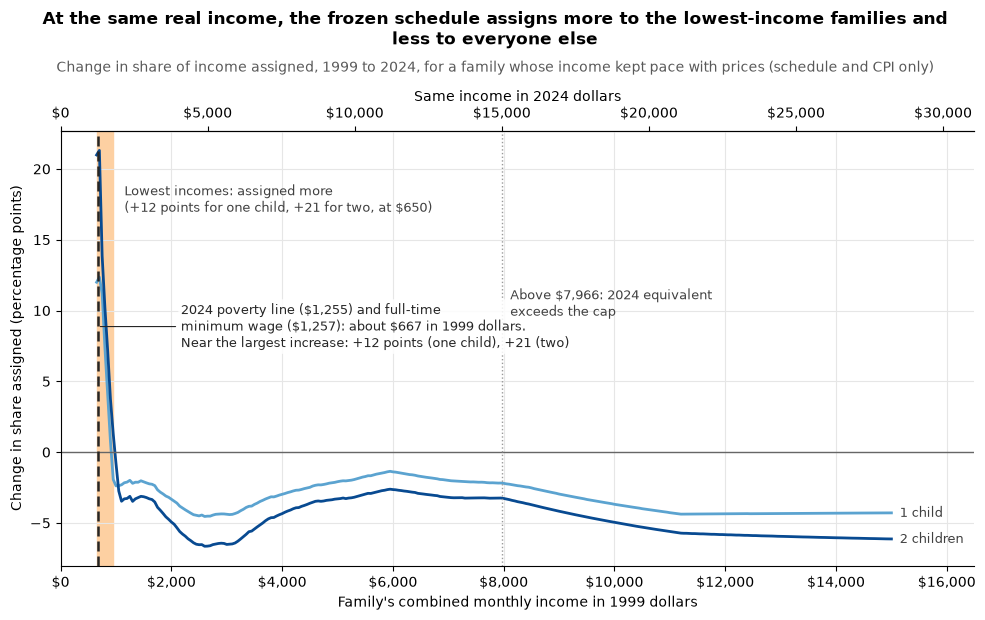

In [22]:
# 1999 incomes from 650 to the cap, restated in 2024 dollars
grid_df = pd.DataFrame({"income_1999": np.arange(PHASE_IN_START, INCOME_CAP + 1, 50,
                                                 dtype=float)})
grid_df["income_2024"] = grid_df["income_1999"] * DEFLATOR_US
for n_children in CHILD_SCENARIOS:
    for income_column in ["income_1999", "income_2024"]:
        lookup_df = pd.DataFrame({"income": grid_df[income_column], "n_children": n_children})
        grid_df[f"share_{income_column}_{n_children}"] = (assign_schedule(lookup_df, "income")
                                                         / lookup_df["income"])

fig, ax = plt.subplots(figsize=(10, 5.5))
change_at_start = {}
for n_children, color in zip(CHILD_SCENARIOS, [plt.cm.Blues(0.55), plt.cm.Blues(0.9)]):
    change = (grid_df[f"share_income_2024_{n_children}"]
              - grid_df[f"share_income_1999_{n_children}"]) * 100
    change_at_start[n_children] = change.iloc[0]
    child_word = "child" if n_children == 1 else "children"
    ax.plot(grid_df["income_1999"], change, color=color, linewidth=2)
    # Label each line at its right end
    ax.annotate(f"{n_children} {child_word}", (grid_df["income_1999"].iloc[-1], change.iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9,
                color="0.25")
ax.axhline(0, color="0.4", linewidth=1)

# Shade the low-income range where the frozen schedule now assigns more (one child)
change_one_child = (grid_df["share_income_2024_1"] - grid_df["share_income_1999_1"])
first_decline = grid_df.loc[change_one_child <= 0, "income_1999"].iloc[0]
ax.axvspan(PHASE_IN_START, first_decline, color=plt.cm.Oranges(0.25), zorder=0)
ax.annotate(f"Lowest incomes: assigned more\n(+{change_at_start[1]:.0f} points for one child, "
            f"+{change_at_start[2]:.0f} for two, at {dollars(PHASE_IN_START)})",
            (first_decline, change_at_start[2] * 0.85), xytext=(8, 0),
            textcoords="offset points", va="center", fontsize=9, color="0.25")

# Mark the 2024 one-person poverty line and full-time minimum wage, in 1999 dollars.
# Both fall inside the range where the frozen schedule now assigns a larger share.
poverty_line_real = POVERTY_GUIDELINE_MONTHLY[CURRENT_YEAR] / DEFLATOR_US
# Change in share assigned at that real income, for one and two children
poverty_change = {}
for n_children in CHILD_SCENARIOS:
    poverty_df = pd.DataFrame({"income": [poverty_line_real, poverty_line_real * DEFLATOR_US],
                               "n_children": n_children})
    poverty_share = assign_schedule(poverty_df, "income") / poverty_df["income"]
    poverty_change[n_children] = (poverty_share.iloc[1] - poverty_share.iloc[0]) * 100
ax.axvline(poverty_line_real, color="0.15", linewidth=1.8, linestyle=(0, (4, 2)), zorder=3)
ax.annotate(f"2024 poverty line ({dollars(POVERTY_GUIDELINE_MONTHLY[CURRENT_YEAR])}) and "
            f"full-time\nminimum wage ({dollars(MIN_WAGE_MONTHLY[CURRENT_YEAR])}): about "
            f"{dollars(poverty_line_real)} in 1999 dollars.\nNear the largest increase: "
            f"+{poverty_change[1]:.0f} points (one child), +{poverty_change[2]:.0f} (two)",
            (poverty_line_real, 0.55), xycoords=("data", "axes fraction"), xytext=(60, 0),
            textcoords="offset points", va="center", fontsize=9, color="0.15",
            bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "alpha": 0.85,
                  "edgecolor": "none"},
            arrowprops={"arrowstyle": "-", "color": "0.15", "linewidth": 0.8})

# Mark where the 2024 equivalent income reaches the cap
cap_in_1999_dollars = INCOME_CAP / DEFLATOR_US
ax.axvline(cap_in_1999_dollars, color="0.6", linewidth=1, linestyle=":")
ax.annotate(f"Above {dollars(cap_in_1999_dollars)}: 2024 equivalent\nexceeds the cap",
            (cap_in_1999_dollars, change_at_start[2] * 0.5), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=9, color="0.25")

# Second axis on top: the same incomes in 2024 dollars
top_axis = ax.secondary_xaxis("top", functions=(lambda income: income * DEFLATOR_US,
                                                lambda income: income / DEFLATOR_US))
top_axis.set_xlabel("Same income in 2024 dollars")
top_axis.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))

ax.set_xlabel("Family's combined monthly income in 1999 dollars")
ax.set_ylabel("Change in share assigned (percentage points)")
ax.set_xlim(0, INCOME_CAP * 1.1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax.grid(color="0.9", linewidth=0.8)
ax.spines[["right"]].set_visible(False)
fig.tight_layout()
add_figure_titles(fig, "At the same real income, the frozen schedule assigns more to the "
                  "lowest-income families and less to everyone else",
                  "Change in share of income assigned, 1999 to 2024, for a family whose "
                  "income kept pace with prices (schedule and CPI only)")
plt.show()

In [23]:
# The phase-in's starting point against the one-person federal poverty guideline
poverty_rows = []
for year in [BASE_YEAR, CURRENT_YEAR]:
    poverty_line = POVERTY_GUIDELINE_MONTHLY[year]
    poverty_rows.append({
        "Year": year,
        "Poverty guideline, one person (monthly)": poverty_line,
        "Phase-in starts at": PHASE_IN_START,
        "Phase-in start as share of poverty guideline": PHASE_IN_START / poverty_line,
        "Imputed minimum wage (monthly)": MIN_WAGE_MONTHLY[year],
        "Minimum wage as share of poverty guideline": MIN_WAGE_MONTHLY[year] / poverty_line,
    })
poverty_df = pd.DataFrame(poverty_rows)
print("The schedule's low-income thresholds against the federal poverty guideline "
      "(nominal dollars)")
display(poverty_df.style.hide(axis="index").format({
    "Poverty guideline, one person (monthly)": "${:,.0f}",
    "Phase-in starts at": "${:,.0f}",
    "Phase-in start as share of poverty guideline": "{:.0%}",
    "Imputed minimum wage (monthly)": "${:,.0f}",
    "Minimum wage as share of poverty guideline": "{:.0%}",
}))

The schedule's low-income thresholds against the federal poverty guideline (nominal dollars)


Year,"Poverty guideline, one person (monthly)",Phase-in starts at,Phase-in start as share of poverty guideline,Imputed minimum wage (monthly),Minimum wage as share of poverty guideline
1999,$687,$650,95%,$893,130%
2024,"$1,255",$650,52%,"$1,257",100%


In [24]:
# Scenario: one parent is imputed at full-time minimum wage; the other parent's income is
# half of the family income at selected percentiles (an illustrative stand-in)
SCENARIO_PERCENTILES = [10, 25, 50, 75, 90]
scenario_rows = []
for percentile in SCENARIO_PERCENTILES:
    for year, income_column in [(BASE_YEAR, "income_1999"), (CURRENT_YEAR, "income_2024")]:
        family_income = percentiles_df.loc[percentiles_df["percentile"] == percentile,
                                           income_column].iloc[0]
        scenario_rows.append({"percentile": percentile, "year": year,
                              "other_parent": family_income / 2,
                              "imputed_parent": MIN_WAGE_MONTHLY[year]})
scenario_df = pd.DataFrame(scenario_rows)
scenario_df["combined"] = scenario_df["other_parent"] + scenario_df["imputed_parent"]
scenario_df["n_children"] = 1
scenario_df["total_support"] = assign_schedule(scenario_df, "combined")
# Income shares: the imputed parent owes their share of combined income
scenario_df["imputed_parent_owes"] = (scenario_df["total_support"]
                                      * scenario_df["imputed_parent"] / scenario_df["combined"])
scenario_df["owed_share_of_imputed_income"] = (scenario_df["imputed_parent_owes"]
                                               / scenario_df["imputed_parent"])

# Labeled, formatted display table
display_df = pd.DataFrame({
    "Percentile (other parent)": scenario_df["percentile"],
    "Year": scenario_df["year"],
    "Other parent's income": scenario_df["other_parent"].map("${:,.0f}".format),
    "Imputed parent's income (min. wage)": scenario_df["imputed_parent"].map("${:,.0f}".format),
    "Combined income": scenario_df["combined"].map("${:,.0f}".format),
    "Total support, 1 child": scenario_df["total_support"].map("${:,.0f}".format),
    "Imputed parent owes": scenario_df["imputed_parent_owes"].map("${:,.0f}".format),
    "Owed as % of imputed parent's income":
        scenario_df["owed_share_of_imputed_income"].map("{:.1%}".format),
})
print("Monthly amounts, nominal dollars of each year. One child.")
display(display_df.style.hide(axis="index"))

# The imputed income itself, in base-year dollars
print(f"Imputed income: ${MIN_WAGE_MONTHLY[BASE_YEAR]:,} in {BASE_YEAR}; "
      f"${MIN_WAGE_MONTHLY[CURRENT_YEAR]:,} in {CURRENT_YEAR}, "
      f"or ${MIN_WAGE_MONTHLY[CURRENT_YEAR] / DEFLATOR_US:,.0f} in {BASE_YEAR} dollars")

Monthly amounts, nominal dollars of each year. One child.


Percentile (other parent),Year,Other parent's income,Imputed parent's income (min. wage),Combined income,"Total support, 1 child",Imputed parent owes,Owed as % of imputed parent's income
10,1999,$733,$893,"$1,626",$304,$167,18.7%
10,2024,"$1,458","$1,257","$2,715",$472,$219,17.4%
25,1999,"$1,175",$893,"$2,068",$374,$162,18.1%
25,2024,"$2,500","$1,257","$3,757",$564,$189,15.0%
50,1999,"$1,875",$893,"$2,768",$477,$154,17.2%
50,2024,"$3,958","$1,257","$5,215",$673,$162,12.9%
75,1999,"$2,733",$893,"$3,626",$553,$136,15.2%
75,2024,"$5,917","$1,257","$7,174",$842,$148,11.7%
90,1999,"$3,927",$893,"$4,820",$636,$118,13.2%
90,2024,"$8,583","$1,257","$9,840","$1,076",$137,10.9%


Imputed income: $893 in 1999; $1,257 in 2024, or $668 in 1999 dollars


### What indexing would have meant

Applying a price-indexed version of the 1999 schedule to the same 2024 families measures what the
freeze has cost in presumptive support. Mean support is \$1,217 a month under the frozen
schedule and \$1,587 under the indexed one, a gap of \$370 a month per family. Indexing to each
family's 1999 position in the income distribution gives \$1,689. In constant dollars, the median
one-child family's presumptive support is 12% lower than in 1999.

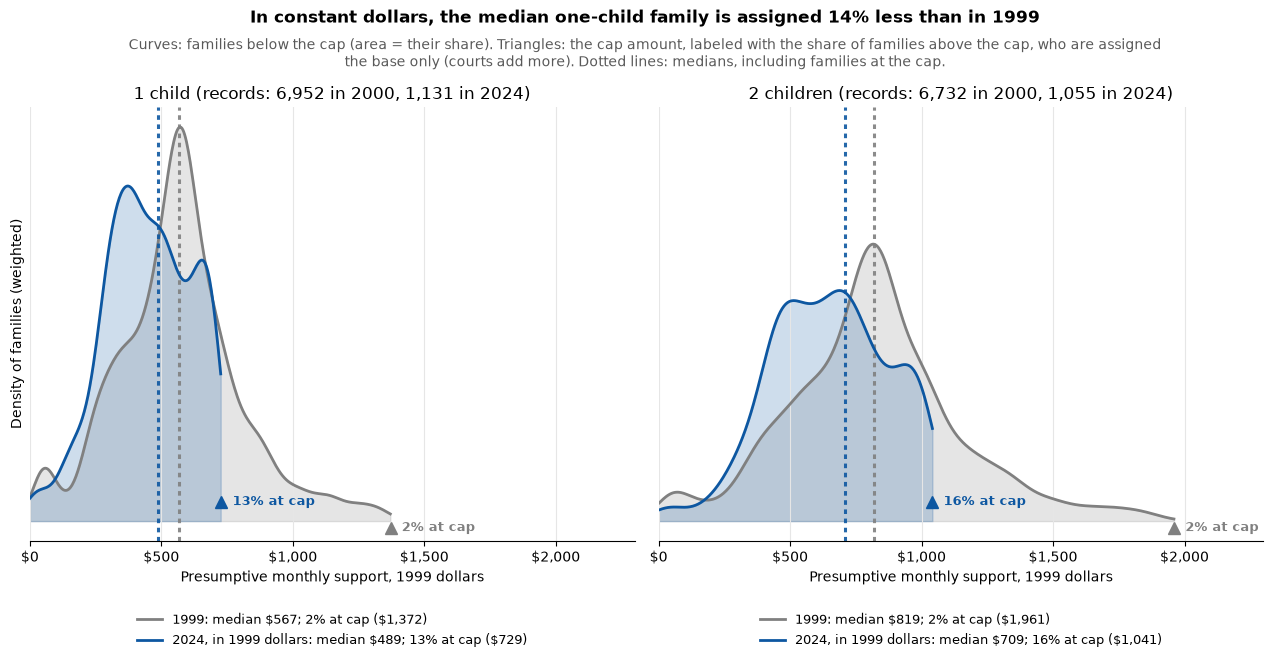

In [25]:
# Presumptive support in base-year (1999) dollars
analysis_df["support_real"] = np.where(analysis_df["YEAR"] == 2024,
                                       analysis_df["support_amount"] / DEFLATOR_US,
                                       analysis_df["support_amount"])

SUPPORT_GRID = np.linspace(0, 2100, 600)


def plot_support_density(ax, values, weights, at_cap, cap_amount, color, label,
                         filled=True, linestyle="-", marker_row=0):
    """Draw a weighted density for families below the cap and mark the cap amount.

    The curve stops at the cap amount (no family below the cap is assigned more) and is
    rescaled so its area equals the share of families below the cap. Families at the cap
    are marked with a triangle at the cap amount, labeled with their share.
    Returns the weighted median of all families, including those at the cap.
    """
    share_at_cap = weights[at_cap].sum() / weights.sum()
    kde = gaussian_kde(values[~at_cap], weights=weights[~at_cap])
    density = kde(SUPPORT_GRID)
    density[SUPPORT_GRID > cap_amount] = 0
    density *= (1 - share_at_cap) / np.trapezoid(density, SUPPORT_GRID)
    # Past the cap there is no curve at all (a flat line at zero would read as data)
    density[SUPPORT_GRID > cap_amount] = np.nan
    median = weighted_quantile(values, weights, 0.5)

    if filled:
        ax.fill_between(SUPPORT_GRID, density, color=color, alpha=0.2)
    ax.plot(SUPPORT_GRID, density, color=color, linewidth=2, linestyle=linestyle,
            label=f"{label}: median {dollars(median)}; {share_at_cap:.0%} at cap "
                  f"({dollars(cap_amount)})")
    # Heavier dotted median line
    ax.axvline(median, color=color, linestyle=(0, (1.5, 1.5)), linewidth=2.2, alpha=0.9)
    # Triangle at the cap amount, stacked by row so markers at the same amount stay visible,
    # labeled with the share of families at the cap
    marker_height = 0.03 + 0.06 * marker_row
    ax.plot(cap_amount, marker_height, marker="^", markersize=9, color=color,
            transform=ax.get_xaxis_transform(), clip_on=False, zorder=5)
    ax.annotate(f"{share_at_cap:.0%} at cap", (cap_amount, marker_height),
                xycoords=("data", "axes fraction"), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, fontweight="bold", color=color, zorder=5)
    return median


YEAR_STYLES = {2000: {"label": "1999", "color": "0.5"},
               2024: {"label": "2024, in 1999 dollars", "color": plt.cm.Blues(0.85)}}

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
medians = {}
for ax, n_children in zip(axes, CHILD_SCENARIOS):
    panel_df = analysis_df[analysis_df["n_children"] == n_children]
    cap_amount = schedule_long_df.loc[
        (schedule_long_df["combined_monthly_income"] == INCOME_CAP)
        & (schedule_long_df["n_children"] == n_children), "total_support_amount"].iloc[0]
    for marker_row, (year, style) in enumerate(YEAR_STYLES.items()):
        year_df = panel_df[panel_df["YEAR"] == year]
        cap_amount_real = cap_amount / DEFLATOR_US if year == 2024 else cap_amount
        medians[(n_children, year)] = plot_support_density(
            ax, year_df["support_real"], year_df["weight"], year_df["above_cap"],
            cap_amount_real, style["color"], style["label"], marker_row=marker_row)

    child_word = "child" if n_children == 1 else "children"
    records = panel_df.groupby("YEAR").size()
    ax.set_title(f"{n_children} {child_word} "
                 f"(records: {records.get(2000, 0):,} in 2000, {records.get(2024, 0):,} in 2024)")
    ax.set_xlabel("Presumptive monthly support, 1999 dollars")
    ax.set_xlim(0, 2300)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.set_yticks([])
    ax.grid(axis="x", color="0.9", linewidth=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    # Legend below each panel, clear of the curves
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=9)

axes[0].set_ylabel("Density of families (weighted)")
median_drop = 1 - medians[(1, 2024)] / medians[(1, 2000)]
fig.tight_layout()
add_figure_titles(fig, f"In constant dollars, the median one-child family is assigned "
                  f"{median_drop:.0%} less than in 1999",
                  "Curves: families below the cap (area = their share). Triangles: the cap "
                  "amount, labeled with the share of families above the cap, who are assigned\n"
                  "the base only (courts add more). Dotted lines: medians, including families "
                  "at the cap.")
plt.show()

In [26]:
#| include: false
# Colors: frozen (blue) and indexed (orange); 1999 is a gray reference
COLOR_FROZEN = "#1f5aa6"
COLOR_INDEXED = "#c0631a"
COLOR_1999 = "0.45"

# Indexed schedule: every income row and support amount scaled by the CPI ratio
indexed_schedule_df = schedule_long_df[["combined_monthly_income", "n_children",
                                        "total_support_amount"]].copy()
indexed_schedule_df["combined_monthly_income"] *= DEFLATOR_US
indexed_schedule_df["total_support_amount"] *= DEFLATOR_US
indexed_schedule_df.to_csv(DATA_PROCESSED_DIR / "schedule_indexed_2024.csv", index=False)
INDEXED_CAP = INCOME_CAP * DEFLATOR_US


def assign_indexed_schedule(families_df, income_column):
    """Presumptive amount under the indexed schedule, in current-year dollars.

    Equivalent to deflating income to base-year dollars, looking it up on the original
    schedule, and inflating the amount back.
    """
    deflated_df = families_df[[income_column, "n_children"]].copy()
    deflated_df[income_column] = deflated_df[income_column] / DEFLATOR_US
    return assign_schedule(deflated_df, income_column) * DEFLATOR_US


print(f"Indexed cap: {INDEXED_CAP:,.0f} dollars a month (15,000 x {DEFLATOR_US:.3f})")
print(indexed_schedule_df[indexed_schedule_df["combined_monthly_income"]
                          == indexed_schedule_df["combined_monthly_income"].max()]
      .round(0).to_string(index=False))

Indexed cap: 28,243 dollars a month (15,000 x 1.883)
 combined_monthly_income  n_children  total_support_amount
                 28243.0           1                2583.0
                 28243.0           2                3692.0
                 28243.0           3                4340.0
                 28243.0           4                4798.0
                 28243.0           5                5201.0
                 28243.0           6                5564.0


In [27]:
#| include: false
# Apply both schedules to 2024 families; keep everything in 1999 dollars
families_2024_df = analysis_df[analysis_df["YEAR"] == 2024].copy()
families_2024_df["support_frozen_real"] = families_2024_df["support_amount"] / DEFLATOR_US
families_2024_df["support_indexed_real"] = (
    assign_indexed_schedule(families_2024_df, "combined_monthly_income") / DEFLATOR_US)
families_2024_df["above_indexed_cap"] = families_2024_df["combined_monthly_income"] > INDEXED_CAP

# Every family in the analysis sample has an amount under both schedules (see Part 5 setup)
assert families_2024_df["support_indexed_real"].notna().all()

families_1999_df = analysis_df[analysis_df["YEAR"] == 2000]


def weighted_mean(values, weights):
    """Weighted average of values."""
    return np.sum(values * weights) / np.sum(weights)


def weighted_share(flags, weights):
    """Weighted share of rows where flags is True."""
    return weights[flags].sum() / weights.sum()


# Summary: 1999 actual, 2024 frozen, 2024 indexed (all families, all child counts)
summary_rows = {
    "1999 (schedule as enacted)": {
        "Median support": weighted_quantile(families_1999_df["support_amount"],
                                            families_1999_df["weight"], 0.5),
        "Mean support": weighted_mean(families_1999_df["support_amount"],
                                      families_1999_df["weight"]),
        "Families above cap": weighted_share(families_1999_df["above_cap"],
                                             families_1999_df["weight"]),
    },
    "2024, frozen schedule": {
        "Median support": weighted_quantile(families_2024_df["support_frozen_real"],
                                            families_2024_df["weight"], 0.5),
        "Mean support": weighted_mean(families_2024_df["support_frozen_real"],
                                      families_2024_df["weight"]),
        "Families above cap": weighted_share(families_2024_df["above_cap"],
                                             families_2024_df["weight"]),
    },
    "2024, indexed schedule": {
        "Median support": weighted_quantile(families_2024_df["support_indexed_real"],
                                            families_2024_df["weight"], 0.5),
        "Mean support": weighted_mean(families_2024_df["support_indexed_real"],
                                      families_2024_df["weight"]),
        "Families above cap": weighted_share(families_2024_df["above_indexed_cap"],
                                             families_2024_df["weight"]),
    },
}
indexed_summary_df = pd.DataFrame(summary_rows).T
gap = (indexed_summary_df.loc["2024, indexed schedule", "Mean support"]
       - indexed_summary_df.loc["2024, frozen schedule", "Mean support"])
print("Presumptive monthly support, all child counts, 1999 dollars "
      "(above-cap families at the base amount)")
display(indexed_summary_df.style.format({"Median support": "${:,.0f}",
                                         "Mean support": "${:,.0f}",
                                         "Families above cap": "{:.1%}"}))
print(f"Mean gap, indexed minus frozen: ${gap:,.0f} a month in 1999 dollars "
      f"(${gap * DEFLATOR_US:,.0f} in 2024 dollars)")

Presumptive monthly support, all child counts, 1999 dollars (above-cap families at the base amount)


,Median support,Mean support,Families above cap
1999 (schedule as enacted),$717,$765,2.1%
"2024, frozen schedule",$626,$646,13.6%
"2024, indexed schedule",$785,$843,3.9%


Mean gap, indexed minus frozen: $196 a month in 1999 dollars ($370 in 2024 dollars)


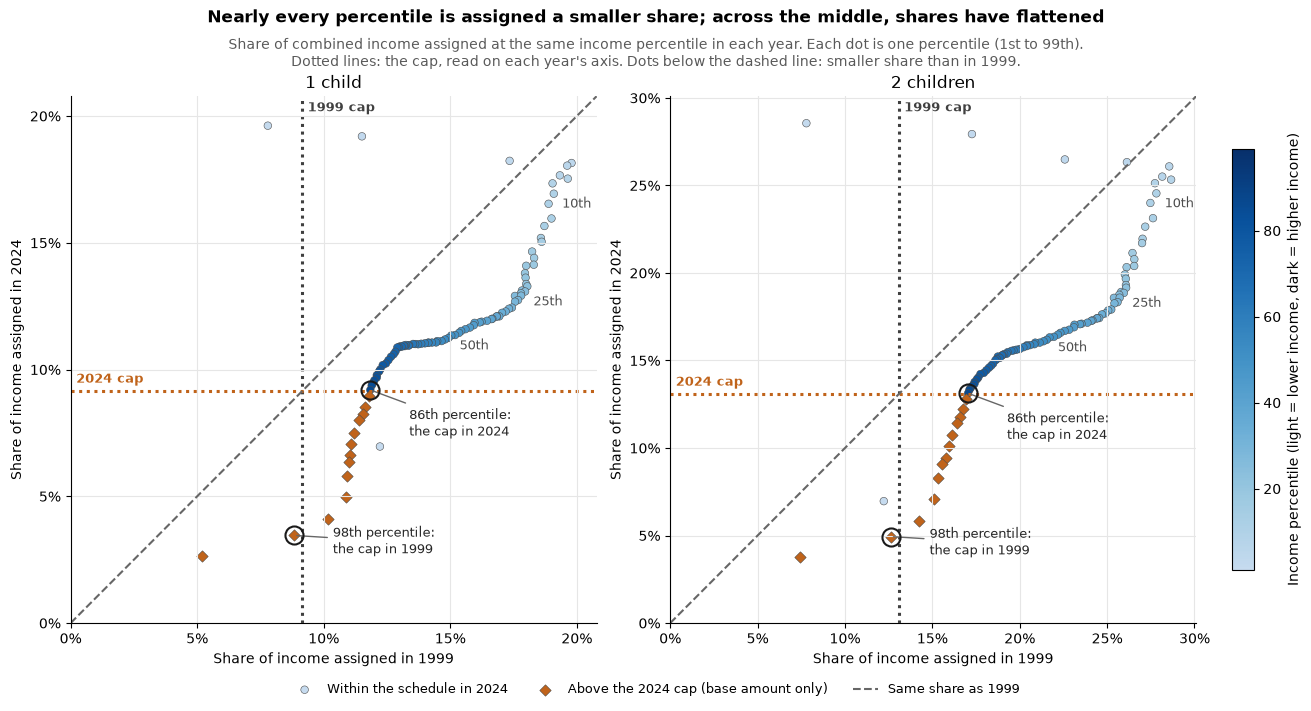

In [28]:
#| include: false
# Share of income assigned at each income percentile, 1999 (x) vs. 2024 (y),
# with each dot shaded by its income percentile
# Blues, starting partway in so the lowest percentiles stay visible on white
PERCENTILE_CMAP = plt.cm.colors.ListedColormap(plt.cm.Blues(np.linspace(0.25, 1.0, 256)))
percentile_norm = plt.Normalize(vmin=1, vmax=99)
COLOR_ABOVE_CAP = "#c0631a"
COLOR_CAP_1999 = "0.25"

fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout="constrained")
for ax, n_children in zip(axes, CHILD_SCENARIOS):
    child_df = share_by_pct_df[share_by_pct_df["n_children"] == n_children]
    above_cap_2024 = child_df["percentile"] >= cap_pct_2024
    within_df = child_df[~above_cap_2024]
    above_df = child_df[above_cap_2024]

    # Circles shaded by percentile: within the schedule in 2024
    dots = ax.scatter(within_df[BASE_YEAR], within_df[CURRENT_YEAR], c=within_df["percentile"],
                      cmap=PERCENTILE_CMAP, norm=percentile_norm, s=30,
                      edgecolors="0.3", linewidths=0.4, label="Within the schedule in 2024")
    # Orange diamonds: above the 2024 cap
    ax.scatter(above_df[BASE_YEAR], above_df[CURRENT_YEAR], color=COLOR_ABOVE_CAP, marker="D",
               s=34, edgecolors="0.3", linewidths=0.4,
               label="Above the 2024 cap (base amount only)")

    # Reference line: the same share in both years
    axis_max = child_df[[BASE_YEAR, CURRENT_YEAR]].max().max() * 1.05
    ax.plot([0, axis_max], [0, axis_max], color="0.4", linestyle="--", linewidth=1.5,
            label="Same share as 1999")

    # The cap: share assigned at exactly 15,000, read on each year's axis
    cap_share = schedule_long_df.loc[
        (schedule_long_df["combined_monthly_income"] == INCOME_CAP)
        & (schedule_long_df["n_children"] == n_children), "support_share"].iloc[0]
    ax.axvline(cap_share, color=COLOR_CAP_1999, linestyle=(0, (1, 1.5)), linewidth=2.2,
               zorder=1)
    ax.axhline(cap_share, color=COLOR_ABOVE_CAP, linestyle=(0, (1, 1.5)), linewidth=2.2,
               zorder=1)
    ax.annotate("1999 cap", (cap_share, 1), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", ha="left", va="top", fontsize=9,
                fontweight="bold", color=COLOR_CAP_1999)
    # 2024 cap label at the left end of its line
    ax.annotate("2024 cap", (0, cap_share), xycoords=("axes fraction", "data"),
                xytext=(4, 4), textcoords="offset points", ha="left", va="bottom",
                fontsize=9, fontweight="bold", color=COLOR_ABOVE_CAP)

    # Label a few percentiles so readers can locate them
    for percentile in [10, 25, 50]:
        row = child_df["percentile"] == percentile
        ax.annotate(ordinal(percentile), (child_df.loc[row, BASE_YEAR].iloc[0],
                                        child_df.loc[row, CURRENT_YEAR].iloc[0]),
                    xytext=(6, -10), textcoords="offset points", fontsize=9, color="0.3")

    # Ring the percentile where the cap fell in each year
    cap_percentiles = [(int(round(cap_pct_1999)), "1999", (28, -4)),
                       (int(round(cap_pct_2024)), "2024", (28, -24))]
    for percentile, year_label, label_offset in cap_percentiles:
        row = child_df["percentile"] == percentile
        point = (child_df.loc[row, BASE_YEAR].iloc[0], child_df.loc[row, CURRENT_YEAR].iloc[0])
        ax.plot(*point, "o", markersize=13, markerfacecolor="none", markeredgecolor="0.1",
                markeredgewidth=1.5, zorder=6)
        ax.annotate(f"{ordinal(percentile)} percentile:\nthe cap in {year_label}", point,
                    xytext=label_offset, textcoords="offset points", va="center", fontsize=9,
                    color="0.15", arrowprops={"arrowstyle": "-", "color": "0.4"})

    child_word = "child" if n_children == 1 else "children"
    ax.set_title(f"{n_children} {child_word}")
    ax.set_xlim(0, axis_max)
    ax.set_ylim(0, axis_max)
    ax.set_xlabel("Share of income assigned in 1999")
    ax.set_ylabel("Share of income assigned in 2024")
    # Ticks every 5 points so the whole-percent labels are exact
    for axis in [ax.xaxis, ax.yaxis]:
        axis.set_major_locator(plt.MultipleLocator(0.05))
        axis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    ax.grid(color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

# One legend below the figure
legend = add_legend_below(fig, axes[0], ncol=3)
# Circle legend marker in a neutral mid-blue so it doesn't imply a percentile
legend.legend_handles[0].set_facecolor(PERCENTILE_CMAP(0.7))

# One color bar for both panels
colorbar = fig.colorbar(dots, ax=axes, shrink=0.8, pad=0.02)
colorbar.set_label("Income percentile (light = lower income, dark = higher income)")

add_figure_titles(fig, "Nearly every percentile is assigned a smaller share; across the "
                  "middle, shares have flattened",
                  "Share of combined income assigned at the same income percentile in each "
                  "year. Each dot is one percentile (1st to 99th).\nDotted lines: the cap, "
                  "read on each year's axis. Dots below the dashed line: smaller share than in "
                  "1999.")
plt.show()

In [29]:
# Where would a CPI-indexed cap fall in the 2024 income distribution?
indexed_cap_pct = np.interp(INDEXED_CAP, percentiles_df["income_2024"], PERCENTILES)
share_above_indexed = weighted_share(families_2024_df["above_indexed_cap"],
                                     families_2024_df["weight"])



def cap_holding_coverage(income_1999, weight_1999, income_2024, weight_2024):
    """The 2024 income that leaves the same weighted share of families above it as the
    15,000 cap did in 1999. Used for the point estimate and in every bootstrap resample."""
    share_at_or_below_1999 = weight_1999[income_1999 <= INCOME_CAP].sum() / weight_1999.sum()
    return weighted_quantile(income_2024, weight_2024, share_at_or_below_1999)


# Cap needed in 2024 to sit at the same position as in 1999
sample_1999 = analysis_df[analysis_df["YEAR"] == 2000]
sample_2024 = analysis_df[analysis_df["YEAR"] == 2024]
cap_same_position = cap_holding_coverage(
    sample_1999["combined_monthly_income"].to_numpy(), sample_1999["weight"].to_numpy(),
    sample_2024["combined_monthly_income"].to_numpy(), sample_2024["weight"].to_numpy())

print(f"1999 cap ({INCOME_CAP:,.0f}): {cap_pct_1999:.0f}th percentile, "
      f"{coverage_df.loc[2000, 'share_above_cap']:.1%} of families above it")
print(f"2024 frozen cap ({INCOME_CAP:,.0f}): {cap_pct_2024:.0f}th percentile, "
      f"{coverage_df.loc[2024, 'share_above_cap']:.1%} above it")
print(f"2024 CPI-indexed cap ({INDEXED_CAP:,.0f}): {indexed_cap_pct:.0f}th percentile, "
      f"{share_above_indexed:.1%} above it")
# Rounded: this estimate rests on the top few dozen 2024 records (see bootstrap below)
print(f"Cap that would hold 1999 coverage in 2024: roughly "
      f"{round(cap_same_position, -3):,.0f} dollars a month "
      f"(about {cap_same_position / INCOME_CAP:.1f}x the current cap)")

1999 cap (15,000): 98th percentile, 2.1% of families above it
2024 frozen cap (15,000): 86th percentile, 13.6% above it
2024 CPI-indexed cap (28,243): 96th percentile, 3.9% above it
Cap that would hold 1999 coverage in 2024: roughly 40,000 dollars a month (about 2.6x the current cap)


In [30]:
# Bootstrap intervals for the coverage results: resample family records with replacement
# within each sample year, keeping their weights, and recompute each statistic.
# This ignores the surveys' stratified design (STRATA, CLUSTER), so the intervals are
# approximate; IPUMS replicate weights would give design-based standard errors.
BOOTSTRAP_REPS = 500
BOOTSTRAP_SEED = 90819

income_by_sample = {year: group_df["combined_monthly_income"].to_numpy()
                    for year, group_df in analysis_df.groupby("YEAR")}
weight_by_sample = {year: group_df["weight"].to_numpy()
                    for year, group_df in analysis_df.groupby("YEAR")}


def coverage_statistics(income_1999, weight_1999, income_2024, weight_2024):
    """Shares above the cap in each year, and the 2024 cap that holds 1999 coverage."""
    share_above_1999 = weight_1999[income_1999 > INCOME_CAP].sum() / weight_1999.sum()
    share_above_2024 = weight_2024[income_2024 > INCOME_CAP].sum() / weight_2024.sum()
    # Same function as the point estimate above, so the two always agree
    cap_estimate = cap_holding_coverage(income_1999, weight_1999, income_2024, weight_2024)
    return share_above_1999, share_above_2024, cap_estimate


rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_results = []
for _ in range(BOOTSTRAP_REPS):
    draw_1999 = rng.integers(0, len(income_by_sample[2000]), len(income_by_sample[2000]))
    draw_2024 = rng.integers(0, len(income_by_sample[2024]), len(income_by_sample[2024]))
    bootstrap_results.append(coverage_statistics(
        income_by_sample[2000][draw_1999], weight_by_sample[2000][draw_1999],
        income_by_sample[2024][draw_2024], weight_by_sample[2024][draw_2024]))
bootstrap_df = pd.DataFrame(bootstrap_results, columns=["share_above_1999",
                                                        "share_above_2024",
                                                        "cap_holding_coverage"])

# Point estimates from the full sample, with 95 percent percentile intervals
point_estimates = coverage_statistics(income_by_sample[2000], weight_by_sample[2000],
                                      income_by_sample[2024], weight_by_sample[2024])
interval_df = pd.DataFrame({
    "Estimate": point_estimates,
    "95% interval, low": bootstrap_df.quantile(0.025).to_numpy(),
    "95% interval, high": bootstrap_df.quantile(0.975).to_numpy(),
}, index=["Share above cap, 1999", "Share above cap, 2024",
          "Cap that holds 1999 coverage (monthly)"])
print(f"Bootstrap intervals ({BOOTSTRAP_REPS} resamples of family records; approximate)")
display(interval_df.style.format("{:.1%}", subset=pd.IndexSlice[interval_df.index[:2], :])
        .format("${:,.0f}", subset=pd.IndexSlice[interval_df.index[2:], :]))

Bootstrap intervals (500 resamples of family records; approximate)


,Estimate,"95% interval, low","95% interval, high"
"Share above cap, 1999",2.1%,1.8%,2.4%
"Share above cap, 2024",13.6%,12.1%,15.4%
Cap that holds 1999 coverage (monthly),"$39,630","$33,123","$47,543"


In [31]:
# Bootstrap interval for the net area between the share curves (the average change in share).
# Each resample redraws families within each year, recomputes both years' income percentiles,
# and applies the schedule again. Expect this cell to take 10 to 20 seconds.


def percentile_shares(income, weight, n_children):
    """Share of income assigned at income percentiles 1 to 99 for one sample."""
    percentile_income = weighted_quantile(income, weight, PERCENTILES / 100)
    lookup_df = pd.DataFrame({"income": percentile_income, "n_children": n_children})
    return (assign_schedule(lookup_df, "income") / lookup_df["income"]).to_numpy()


def area_statistics(income_1999, weight_1999, income_2024, weight_2024):
    """Net area (points) and relative change in average share, for each child count."""
    results = {}
    for n_children in CHILD_SCENARIOS:
        share_1999 = percentile_shares(income_1999, weight_1999, n_children)
        share_2024 = percentile_shares(income_2024, weight_2024, n_children)
        results[n_children] = ((share_2024 - share_1999).mean() * 100,
                               share_2024.mean() / share_1999.mean() - 1)
    return results


# Full-sample estimates (these match the area table above)
area_estimates = area_statistics(income_by_sample[2000], weight_by_sample[2000],
                                 income_by_sample[2024], weight_by_sample[2024])

rng = np.random.default_rng(BOOTSTRAP_SEED + 1)
area_draws = {n_children: [] for n_children in CHILD_SCENARIOS}
for _ in range(BOOTSTRAP_REPS):
    draw_1999 = rng.integers(0, len(income_by_sample[2000]), len(income_by_sample[2000]))
    draw_2024 = rng.integers(0, len(income_by_sample[2024]), len(income_by_sample[2024]))
    rep_results = area_statistics(
        income_by_sample[2000][draw_1999], weight_by_sample[2000][draw_1999],
        income_by_sample[2024][draw_2024], weight_by_sample[2024][draw_2024])
    for n_children in CHILD_SCENARIOS:
        area_draws[n_children].append(rep_results[n_children])

area_interval_rows = []
for n_children in CHILD_SCENARIOS:
    draws = np.array(area_draws[n_children])
    net_estimate, relative_estimate = area_estimates[n_children]
    bootstrap_se = draws[:, 0].std(ddof=1)
    area_interval_rows.append({
        "Children": n_children,
        "Net area (points)": net_estimate,
        "Bootstrap SE": bootstrap_se,
        "95% normal interval, low": net_estimate - 1.96 * bootstrap_se,
        "95% normal interval, high": net_estimate + 1.96 * bootstrap_se,
        "95% percentile interval, low": np.percentile(draws[:, 0], 2.5),
        "95% percentile interval, high": np.percentile(draws[:, 0], 97.5),
        "Relative change": relative_estimate,
        "Relative change, 95% low": np.percentile(draws[:, 1], 2.5),
        "Relative change, 95% high": np.percentile(draws[:, 1], 97.5),
    })

area_interval_df = pd.DataFrame(area_interval_rows)
print(f"Net area between the share curves: {BOOTSTRAP_REPS} bootstrap resamples "
      "(approximate; ignores survey strata and clusters)")
display(area_interval_df.style.hide(axis="index").format({
    "Net area (points)": "{:+.2f}",
    "Bootstrap SE": "{:.2f}",
    "95% normal interval, low": "{:+.2f}",
    "95% normal interval, high": "{:+.2f}",
    "95% percentile interval, low": "{:+.2f}",
    "95% percentile interval, high": "{:+.2f}",
    "Relative change": "{:+.1%}",
    "Relative change, 95% low": "{:+.1%}",
    "Relative change, 95% high": "{:+.1%}",
}))

Net area between the share curves: 500 bootstrap resamples (approximate; ignores survey strata and clusters)


Children,Net area (points),Bootstrap SE,"95% normal interval, low","95% normal interval, high","95% percentile interval, low","95% percentile interval, high",Relative change,"Relative change, 95% low","Relative change, 95% high"
1,-3.17,0.09,-3.35,-2.98,-3.32,-2.97,-21.4%,-22.4%,-20.0%
2,-4.62,0.13,-4.89,-4.36,-4.84,-4.34,-21.8%,-22.7%,-20.4%


Mean presumptive support per 2024 family, 2024 dollars: frozen $1,217; indexed to prices $1,587; indexed to 1999 position $1,689


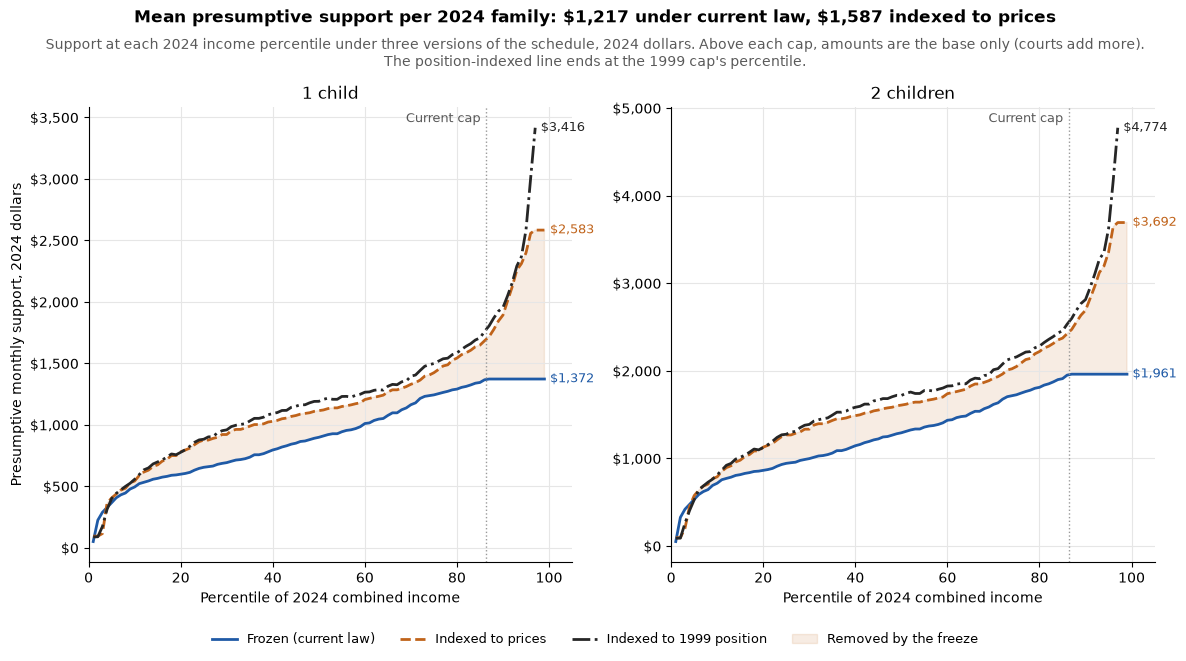

Presumptive monthly support for 2024 families, 2024 dollars


Children,Percentile,2024 income,Frozen,Indexed to prices,Indexed to 1999 position,Position vs. frozen
1,10,"$2,917",$494,$542,$557,+13%
1,25,"$5,000",$654,$876,$882,+35%
1,50,"$7,917",$898,"$1,115","$1,191",+33%
1,75,"$11,833","$1,243","$1,423","$1,498",+21%
1,90,"$17,167","$1,372","$1,892","$1,954",+42%
2,10,"$2,917",$716,$789,$811,+13%
2,25,"$5,000",$943,"$1,267","$1,275",+35%
2,50,"$7,917","$1,292","$1,608","$1,718",+33%
2,75,"$11,833","$1,726","$2,049","$2,158",+25%
2,90,"$17,167","$1,961","$2,691","$2,813",+43%


In [32]:
# Position-indexed schedule: a 2024 family is assigned the share of income that the 1999
# schedule assigned a family at the same percentile of the 1999 income distribution
# Near-black dash-dot, distinct from blue and orange for all color vision
COLOR_POSITION = "0.15"
FINE_PERCENTILES = np.arange(0.5, 100, 0.5)
fine_income = {
    year: weighted_quantile(group_df["combined_monthly_income"], group_df["weight"],
                            FINE_PERCENTILES / 100)
    for year, group_df in analysis_df.groupby("YEAR")
}


def map_to_1999_position(income_2024):
    """Return the 1999 income at the same percentile as each 2024 income."""
    percentile = np.interp(income_2024, fine_income[2024], FINE_PERCENTILES)
    return np.interp(percentile, FINE_PERCENTILES, fine_income[2000])


def assign_position_schedule(families_df, income_column):
    """Presumptive amount under the position-indexed schedule, in 2024 dollars."""
    mapped_df = families_df[[income_column, "n_children"]].copy()
    mapped_df["income_1999_equivalent"] = map_to_1999_position(mapped_df[income_column])
    share_1999 = (assign_schedule(mapped_df, "income_1999_equivalent")
                  / mapped_df["income_1999_equivalent"])
    return share_1999 * mapped_df[income_column]


# Per-family averages across all 2024 families and child counts
families_2024_df["support_position"] = assign_position_schedule(families_2024_df,
                                                                "combined_monthly_income")
mean_frozen = weighted_mean(families_2024_df["support_amount"], families_2024_df["weight"])
mean_indexed = weighted_mean(families_2024_df["support_indexed_real"] * DEFLATOR_US,
                             families_2024_df["weight"])
mean_position = weighted_mean(families_2024_df["support_position"], families_2024_df["weight"])
print(f"Mean presumptive support per 2024 family, 2024 dollars: frozen ${mean_frozen:,.0f}; "
      f"indexed to prices ${mean_indexed:,.0f}; indexed to 1999 position ${mean_position:,.0f}")

# Support at each 2024 percentile under the three schedules, in 2024 dollars
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=False)
comparison_rows = []
# The position-indexed schedule has no formula amount past the 1999 cap's percentile
within_1999_schedule = PERCENTILES <= cap_pct_1999
for ax, n_children in zip(axes, CHILD_SCENARIOS):
    pct_df = pd.DataFrame({"income": percentiles_df["income_2024"], "n_children": n_children})
    frozen = assign_schedule(pct_df, "income")
    indexed = assign_indexed_schedule(pct_df, "income")
    position = assign_position_schedule(pct_df, "income")
    # The position-indexed line stops at the 1999 cap's percentile
    series = [(PERCENTILES, frozen, COLOR_FROZEN, "-", "Frozen (current law)"),
              (PERCENTILES, indexed, COLOR_INDEXED, "--", "Indexed to prices"),
              (PERCENTILES[within_1999_schedule], position[within_1999_schedule],
               COLOR_POSITION, "-.", "Indexed to 1999 position")]
    for x_values, values, color, style, label in series:
        ax.plot(x_values, values, color=color, linestyle=style, linewidth=2, label=label)
        # Direct label at the right end of each line
        ax.annotate(f"${values.iloc[-1]:,.0f}", (x_values[-1], values.iloc[-1]),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=9,
                    color=color)
    # Shade what the freeze removed, measured against price indexing
    ax.fill_between(PERCENTILES, frozen, indexed, where=indexed > frozen, color=COLOR_INDEXED,
                    alpha=0.12, interpolate=True, label="Removed by the freeze")
    ax.axvline(cap_pct_2024, color="0.6", linestyle=":", linewidth=1)
    ax.annotate("Current cap", (cap_pct_2024, ax.get_ylim()[1]), xytext=(-4, -4),
                textcoords="offset points", ha="right", va="top", fontsize=9, color="0.35")
    for percentile in [10, 25, 50, 75, 90]:
        row = PERCENTILES == percentile
        comparison_rows.append({"Children": n_children, "Percentile": percentile,
                                "2024 income": pct_df["income"][row].iloc[0],
                                "Frozen": frozen[row].iloc[0],
                                "Indexed to prices": indexed[row].iloc[0],
                                "Indexed to 1999 position": position[row].iloc[0]})
    child_word = "child" if n_children == 1 else "children"
    ax.set_title(f"{n_children} {child_word}")
    ax.set_xlabel("Percentile of 2024 combined income")
    ax.set_xlim(0, 105)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.grid(color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Presumptive monthly support, 2024 dollars")
fig.tight_layout()
add_legend_below(fig, axes[0], ncol=4)
add_figure_titles(fig, f"Mean presumptive support per 2024 family: {dollars(mean_frozen)} "
                  f"under current law, {dollars(mean_indexed)} indexed to prices",
                  "Support at each 2024 income percentile under three versions of the schedule, "
                  "2024 dollars. Above each cap, amounts are the base only (courts add more).\n"
                  "The position-indexed line ends at the 1999 cap's percentile.")
plt.show()

# Table at selected percentiles
comparison_df = pd.DataFrame(comparison_rows)
comparison_df["Position vs. frozen"] = (comparison_df["Indexed to 1999 position"]
                                        / comparison_df["Frozen"] - 1)
print("Presumptive monthly support for 2024 families, 2024 dollars")
display(comparison_df.style.hide(axis="index").format({
    "2024 income": "${:,.0f}", "Frozen": "${:,.0f}", "Indexed to prices": "${:,.0f}",
    "Indexed to 1999 position": "${:,.0f}", "Position vs. frozen": "{:+.0%}",
}))

In [33]:
#| include: false
# Presumptive support at a chosen 2024 combined income, under all three schedules
example_df = pd.DataFrame({"income": [20000.0] * 2, "n_children": CHILD_SCENARIOS})
example_df["Frozen"] = assign_schedule(example_df, "income")
example_df["Indexed to prices"] = assign_indexed_schedule(example_df, "income")
example_df["Indexed to 1999 position"] = assign_position_schedule(example_df, "income")
example_df["2024 percentile"] = np.interp(example_df["income"], fine_income[2024],
                                          FINE_PERCENTILES)
display(example_df.style.hide(axis="index").format({
    "income": "${:,.0f}", "Frozen": "${:,.0f}", "Indexed to prices": "${:,.0f}",
    "Indexed to 1999 position": "${:,.0f}", "2024 percentile": "{:.0f}",
}))

income,n_children,Frozen,Indexed to prices,Indexed to 1999 position,2024 percentile
"$20,000",1,"$1,372","$2,180","$2,212",92
"$20,000",2,"$1,961","$3,031","$3,174",92


### The top of the schedule

In 1999 the schedule's largest one-child amount, \$1,372 a month, was reserved for families
earning \$15,000 a month or more. In real terms it is now worth \$729, what the 1999 schedule
assigned a family earning about \$5,950. The same holds for every child count. Two cap levels would
undo this. A cap of about \$28,000 a month would restore the top amount's 1999 value. A cap of
about \$40,000 would leave the same share of families above it as in 1999, 2.1%, though that
figure rests on a small number of high-income survey records and is rough.

In [34]:
# For each number of children: what the 1999 top of the schedule was worth, what it is worth
# now, and what the top amount would need to be to hold that value
top_rows = []
for n_children in range(1, 7):
    child_schedule_df = schedule_long_df[schedule_long_df["n_children"] == n_children]
    top_amount = child_schedule_df.loc[
        child_schedule_df["combined_monthly_income"] == INCOME_CAP, "total_support_amount"
    ].iloc[0]
    # Today's top amount, measured in 1999 dollars
    top_amount_real = top_amount / DEFLATOR_US
    # The 1999 income that was assigned that same real amount ("equal to or above" rows)
    rows_at_or_below = child_schedule_df[
        child_schedule_df["total_support_amount"] <= top_amount_real]
    equivalent_1999_income = rows_at_or_below["combined_monthly_income"].max()
    top_rows.append({
        "Children": n_children,
        "1999 top amount (at 15,000)": top_amount,
        "Current top, in 1999 dollars": top_amount_real,
        "1999 income that was assigned the current top's value": equivalent_1999_income,
        "Top amount to hold value (CPI), 2024 dollars": top_amount * DEFLATOR_US,
        # Rounded to the nearest 100: the coverage-holding cap is a rough estimate
        "Top amount to hold 1999 coverage, 2024 dollars (rough)":
            round(top_amount / INCOME_CAP * cap_same_position, -2),
    })
top_value_df = pd.DataFrame(top_rows)
top_value_df.to_csv(DATA_PROCESSED_DIR / "top_of_schedule_values.csv", index=False)

print(f"Ceiling to hold value (CPI): {INDEXED_CAP:,.0f} dollars a month")
print(f"Ceiling to hold 1999 coverage: roughly {round(cap_same_position, -3):,.0f} dollars "
      "a month (see the bootstrap interval above)")
print(f"Today's top amounts are worth {1 / DEFLATOR_US:.0%} of their 1999 value.\n")
print("The top of the schedule, by number of children (monthly amounts)")
display(top_value_df.style.hide(axis="index").format({
    "1999 top amount (at 15,000)": "${:,.0f}",
    "Current top, in 1999 dollars": "${:,.0f}",
    "1999 income that was assigned the current top's value": "${:,.0f}",
    "Top amount to hold value (CPI), 2024 dollars": "${:,.0f}",
    "Top amount to hold 1999 coverage, 2024 dollars (rough)": "${:,.0f}",
}))

Ceiling to hold value (CPI): 28,243 dollars a month
Ceiling to hold 1999 coverage: roughly 40,000 dollars a month (see the bootstrap interval above)
Today's top amounts are worth 53% of their 1999 value.

The top of the schedule, by number of children (monthly amounts)


Children,"1999 top amount (at 15,000)","Current top, in 1999 dollars",1999 income that was assigned the current top's value,"Top amount to hold value (CPI), 2024 dollars","Top amount to hold 1999 coverage, 2024 dollars (rough)"
1,"$1,372",$729,"$5,950","$2,583","$3,600"
2,"$1,961","$1,041","$5,850","$3,692","$5,200"
3,"$2,305","$1,224","$5,900","$4,340","$6,100"
4,"$2,548","$1,353","$5,900","$4,798","$6,700"
5,"$2,762","$1,467","$5,900","$5,201","$7,300"
6,"$2,955","$1,569","$5,900","$5,564","$7,800"


## 6. Recommendations

The schedule is Oklahoma's statement of what children are owed from their parents' income. Keeping
that statement current takes two steps.

**Maintenance the data supports now**

1. Index the income brackets and support amounts to CPI-U between reviews, so the table holds its
   value without a new vote. Indexing would have added \$370 a month to the average 2024
   family's presumptive support.
2. Tie the start of the phase-in to the federal poverty guideline, so the low-income protection
   keeps pace with poverty.
3. Raise the cap to about \$28,000 a month to restore its value. Restoring 1999 coverage
   would take roughly \$40,000.

**The structural fix**

4. Require each quadrennial review to update the dollar amounts from a current study of what
   raising children costs. Indexing assumes those costs grew with general prices, which this
   analysis does not test. The review should also revisit imputed income, since a full-time
   minimum wage unchanged since 2009 now imputes 25% less than in 1999.

Each change keeps a child's presumptive support from shrinking by default.

## 7. Limitations

**Unit of analysis.** The schedule applies to parents who live apart, but the census observes both
parents' incomes only when they live together, so married couples stand in for separated parents.
Separated parents earn less on average, so this analysis likely overstates the share above the cap
and understates the share in the phase-in. The direction of each result should hold; the magnitudes
describe married couples, not support cases.

**Sampling and measurement.** The 2024 sample has about 2,900 families, so results that rest on the
top percentiles, especially the \$40,000 cap, are rough, and the bootstrap ignores the survey design.
Census income approximates the guideline's definition of gross income, and the two surveys top-code
high incomes differently. The minimum-wage scenarios use half of a couple's income as a stand-in
for the other parent.

**Presumptive amounts only.** All amounts come before adjustments for child care, health insurance,
parenting time, or judicial deviation. Above the cap, courts add amounts this analysis cannot
observe.

## 8. Future work

- Design-based standard errors using IPUMS replicate weights.
- Single-parent households as a second unit of analysis.
- A decomposition of the change in share assigned into a price effect (same real income) and a
  real-growth effect (same percentile).
- A comparison against current estimates of the cost of raising a child, which an updated schedule
  would be built from.
- Whether the \$50 minimum order and the phase-in reflect state cost recovery for public
  assistance, and how a recovery goal should weigh against an order a parent can actually meet.

## Use of generative AI

Under the course's Tier 4 policy, I used Claude (Anthropic) throughout this project: to plan the
analysis, write and debug Python code, design the charts, draft the data dictionary, and shape this
report's prose from my answers to its questions. I set the research question, chose the data
sources, approved each analytic choice, ran every cell, and reviewed every output. Remaining errors
are mine.

[^statute]: Okla. Stat. tit. 43, § 119, current text and as enacted by Laws 1999, c. 422, Oklahoma State Courts Network, retrieved September 25, 2026. A 2000 amendment changed only the bracket rule, from "is over" to "equal to or above."

[^review]: 45 C.F.R. § 302.56(e) requires each state to review its child support guidelines at least once every four years.

[^dhs]: Oklahoma Human Services, *Child Support Guideline Schedule*, Pub. No. 01-38 (rev. 2013), retrieved September 25, 2026.

[^bls]: U.S. Bureau of Labor Statistics, Consumer Price Index for All Urban Consumers (CPI-U), all items, not seasonally adjusted, series CUUR0000SA0 (U.S. city average) and CUUR0300SA0 (South), annual averages, Public Data API v2, retrieved October 9, 2026.

[^ipums]: Steven Ruggles, Sarah Flood, Matthew Sobek, Daniel Backman, Grace Cooper, Julia A. Rivera Drew, Stephanie Richards, Renae Rodgers, Jonathan Schroeder, and Kari C.W. Williams. IPUMS USA: Version 16.0 [dataset]. Minneapolis, MN: IPUMS, 2025. <https://doi.org/10.18128/D010.V16.0>

[^bootstrap]: Bradley Efron and Robert J. Tibshirani, *An Introduction to the Bootstrap* (New York: Chapman & Hall, 1993). Intervals use 500 resamples of family records within each year and ignore the surveys' strata and clusters.

[^bartfeld]: Judi Bartfeld, "Child Support and the Postdivorce Economic Well-being of Mothers, Fathers, and Children," *Demography* 37, no. 2 (2000): 203–13.

[^growth]: Real growth by percentile follows the growth incidence curve of Martin Ravallion and Shaohua Chen, "Measuring Pro-Poor Growth," *Economics Letters* 78, no. 1 (2003): 93–99. The two-sample Q-Q plot follows M. B. Wilk and R. Gnanadesikan, "Probability Plotting Methods for the Analysis of Data," *Biometrika* 55, no. 1 (1968): 1–17.

[^stirling]: Kate Stirling and Tom Aldrich, "Child Support: Who Bears the Burden?" *Family Relations* 57, no. 3 (2008): 376–89, at 378.

[^poverty]: U.S. Department of Health and Human Services, "Annual Update of the HHS Poverty Guidelines," 64 Fed. Reg. 13428 (March 18, 1999) and 89 Fed. Reg. 2961 (January 17, 2024). The one-person guideline for the 48 contiguous states and DC was \$8,240 a year in 1999 and \$15,060 in 2024.

[^minwage]: Fair Labor Standards Act, 29 U.S.C. § 206(a)(1)(C), effective July 24, 2009; Okla. Stat. tit. 40, § 197.2 sets the state minimum wage at the federal rate. Imputed monthly amounts follow the minimum wage table in OKDHS Pub. 01-38.